In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import zipfile

ZIP_PATH = "/content/drive/MyDrive/Edge-IIoTset/archive.zip"

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(
        f"ZIP not found: {ZIP_PATH}\n"
        "Check the folder name and ZIP filename in Google Drive."
    )

print("Archive found!")
print("Size:", round(os.path.getsize(ZIP_PATH) / (1024**3), 2), "GB")

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    files = z.infolist()

    print("\nTotal archive entries:", len(files))

    print("\n========== PCAP / CSV / ARFF FILES ==========")

    for f in files:
        name = f.filename.lower()

        if name.endswith(('.pcap', '.pcapng', '.csv', '.arff', '.zip')):
            print(
                f"{f.filename} | "
                f"{f.file_size / (1024**2):.2f} MB"
            )

Archive found!
Size: 1.63 GB

Total archive entries: 52

========== PCAP / CSV / ARFF FILES ==========
Edge-IIoTset dataset/Attack traffic/Backdoor_attack.csv | 17.06 MB
Edge-IIoTset dataset/Attack traffic/Backdoor_attack.pcap | 6.38 MB
Edge-IIoTset dataset/Attack traffic/DDoS HTTP Flood Attacks.pcap | 27.00 MB
Edge-IIoTset dataset/Attack traffic/DDoS ICMP Flood Attacks.pcap | 202.59 MB
Edge-IIoTset dataset/Attack traffic/DDoS TCP SYN Flood Attacks.pcap | 269.52 MB
Edge-IIoTset dataset/Attack traffic/DDoS UDP Flood Attacks.pcap | 236.09 MB
Edge-IIoTset dataset/Attack traffic/DDoS_HTTP_Flood_attack.csv | 91.28 MB
Edge-IIoTset dataset/Attack traffic/DDoS_ICMP_Flood_attack.csv | 850.75 MB
Edge-IIoTset dataset/Attack traffic/DDoS_TCP_SYN_Flood_attack.csv | 897.59 MB
Edge-IIoTset dataset/Attack traffic/DDoS_UDP_Flood_attack.csv | 858.53 MB
Edge-IIoTset dataset/Attack traffic/MITM (ARP spoofing + DNS) Attack.pcap | 0.12 MB
Edge-IIoTset dataset/Attack traffic/MITM_attack.csv | 0.31 MB
Edge-II

In [ ]:
!pip -q install scapy

In [ ]:
import os
import zipfile
import pandas as pd
from collections import Counter
from scapy.all import PcapReader, ARP, DNS, Ether, IP

ZIP_PATH = "/content/drive/MyDrive/Edge-IIoTset/archive.zip"

MITM_PCAP = "Edge-IIoTset dataset/Attack traffic/MITM (ARP spoofing + DNS) Attack.pcap"
MITM_CSV = "Edge-IIoTset dataset/Attack traffic/MITM_attack.csv"

OUT = "/content/edge_mitm_inspection"
os.makedirs(OUT, exist_ok=True)

# Extract only the two small MITM files
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for name in [MITM_PCAP, MITM_CSV]:
        target = os.path.join(OUT, os.path.basename(name))
        with z.open(name) as src, open(target, "wb") as dst:
            dst.write(src.read())

print("MITM files extracted for inspection.")

MITM files extracted for inspection.


In [ ]:
from scapy.all import PcapReader, ARP, DNS, Ether, IP
from collections import Counter

pcap_path = os.path.join(
    OUT, "MITM (ARP spoofing + DNS) Attack.pcap"
)

total = 0
arp_count = 0
dns_count = 0
arp_opcodes = Counter()
arp_sources = Counter()
arp_targets = Counter()
dns_types = Counter()
timestamps = []

with PcapReader(pcap_path) as packets:
    for pkt in packets:
        total += 1

        if hasattr(pkt, "time"):
            timestamps.append(float(pkt.time))

        if ARP in pkt:
            arp_count += 1
            arp_opcodes[pkt[ARP].op] += 1
            arp_sources[(pkt[ARP].psrc, pkt[ARP].hwsrc)] += 1
            arp_targets[pkt[ARP].pdst] += 1

        if DNS in pkt:
            dns_count += 1
            dns_types[pkt[DNS].qr] += 1

print("========== MITM PCAP ANALYSIS ==========")
print("Total packets:", total)
print("ARP packets:", arp_count)
print("DNS packets:", dns_count)
print("Other packets:", total - arp_count - dns_count)
print("ARP opcodes:", arp_opcodes)
print("ARP sender IP/MAC pairs:", arp_sources.most_common(10))
print("ARP target IPs:", arp_targets.most_common(10))
print("DNS query/response counts:", dns_types)

if timestamps:
    print("Capture duration (seconds):", max(timestamps) - min(timestamps))

========== MITM PCAP ANALYSIS ==========
Total packets: 1229
ARP packets: 341
DNS packets: 302
Other packets: 586
ARP opcodes: Counter({2: 244, 1: 97})
ARP sender IP/MAC pairs: [(('192.168.0.101', 'd8:f2:ca:8e:17:69'), 155), (('192.168.0.152', 'd8:f2:ca:8e:17:69'), 120), (('0.0.0.0', 'd8:f2:ca:8e:17:69'), 58), (('192.168.0.128', 'dc:a6:32:fb:69:b5'), 4), (('192.168.0.1', '48:f9:7c:f6:cb:a1'), 2), (('192.168.0.170', 'd8:f2:ca:8e:17:69'), 2)]
ARP target IPs: [('192.168.0.128', 244), ('192.168.0.101', 76), ('192.168.0.1', 19), ('192.168.0.170', 2)]
DNS query/response counts: Counter({0: 302})
Capture duration (seconds): 1193.6380288600922


In [ ]:
csv_path = os.path.join(OUT, "MITM_attack.csv")

df = pd.read_csv(csv_path)

print("========== MITM CSV ANALYSIS ==========")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nPossible label columns:")
for col in df.columns:
    if any(word in col.lower() for word in ["label", "attack", "category", "class"]):
        print("\nColumn:", col)
        print(df[col].value_counts(dropna=False).head(20))

========== MITM CSV ANALYSIS ==========
Shape: (1229, 63)

Columns:
['frame.time', 'ip.src_host', 'ip.dst_host', 'arp.dst.proto_ipv4', 'arp.opcode', 'arp.hw.size', 'arp.src.proto_ipv4', 'icmp.checksum', 'icmp.seq_le', 'icmp.transmit_timestamp', 'icmp.unused', 'http.file_data', 'http.content_length', 'http.request.uri.query', 'http.request.method', 'http.referer', 'http.request.full_uri', 'http.request.version', 'http.response', 'http.tls_port', 'tcp.ack', 'tcp.ack_raw', 'tcp.checksum', 'tcp.connection.fin', 'tcp.connection.rst', 'tcp.connection.syn', 'tcp.connection.synack', 'tcp.dstport', 'tcp.flags', 'tcp.flags.ack', 'tcp.len', 'tcp.options', 'tcp.payload', 'tcp.seq', 'tcp.srcport', 'udp.port', 'udp.stream', 'udp.time_delta', 'dns.qry.name', 'dns.qry.name.len', 'dns.qry.qu', 'dns.qry.type', 'dns.retransmission', 'dns.retransmit_request', 'dns.retransmit_request_in', 'mqtt.conack.flags', 'mqtt.conflag.cleansess', 'mqtt.conflags', 'mqtt.hdrflags', 'mqtt.len', 'mqtt.msg_decoded_as', 'mq

,frame.time,ip.src_host,ip.dst_host,arp.dst.proto_ipv4,arp.opcode,arp.hw.size,arp.src.proto_ipv4,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,...,mqtt.proto_len,mqtt.protoname,mqtt.topic,mqtt.topic_len,mqtt.ver,mbtcp.len,mbtcp.trans_id,mbtcp.unit_id,Attack_label,Attack_type
0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
1,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
2,6.0,192.168.0.101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
3,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
4,6.0,192.168.0.101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM



Possible label columns:

Column: Attack_label
Attack_label
1    1229
Name: count, dtype: int64

Column: Attack_type
Attack_type
MITM    1229
Name: count, dtype: int64


In [ ]:
from scapy.all import PcapReader, ARP, Ether
from collections import Counter, defaultdict
import pandas as pd
import os

pcap_path = os.path.join(
    OUT, "MITM (ARP spoofing + DNS) Attack.pcap"
)

arp_rows = []

with PcapReader(pcap_path) as packets:
    for i, pkt in enumerate(packets):
        if ARP in pkt:
            a = pkt[ARP]

            arp_rows.append({
                "packet_index": i,
                "timestamp": float(pkt.time),
                "opcode": int(a.op),
                "sender_ip": a.psrc,
                "sender_mac": a.hwsrc.lower(),
                "target_ip": a.pdst,
                "target_mac": a.hwdst.lower(),
                "ethernet_src": pkt[Ether].src.lower() if Ether in pkt else None,
                "ethernet_dst": pkt[Ether].dst.lower() if Ether in pkt else None
            })

arp_df = pd.DataFrame(arp_rows)

print("Total ARP packets:", len(arp_df))

print("\n1. Sender IP-MAC mappings:")
display(
    arp_df.groupby(["sender_ip", "sender_mac"])
    .size().reset_index(name="count")
    .sort_values("count", ascending=False)
)

print("\n2. ARP opcode distribution:")
print(arp_df["opcode"].value_counts())

print("\n3. Most frequent sender MAC addresses:")
print(arp_df["sender_mac"].value_counts())

print("\n4. First 40 ARP packets in capture order:")
display(arp_df.head(40))

print("\n5. ARP packets from the suspicious MAC:")
suspicious_mac = "d8:f2:ca:8e:17:69"

display(
    arp_df[arp_df["sender_mac"] == suspicious_mac].head(60)
)

Total ARP packets: 341

1. Sender IP-MAC mappings:


,sender_ip,sender_mac,count
2,192.168.0.101,d8:f2:ca:8e:17:69,155
4,192.168.0.152,d8:f2:ca:8e:17:69,120
0,0.0.0.0,d8:f2:ca:8e:17:69,58
3,192.168.0.128,dc:a6:32:fb:69:b5,4
1,192.168.0.1,48:f9:7c:f6:cb:a1,2
5,192.168.0.170,d8:f2:ca:8e:17:69,2



2. ARP opcode distribution:
opcode
2    244
1     97
Name: count, dtype: int64

3. Most frequent sender MAC addresses:
sender_mac
d8:f2:ca:8e:17:69    335
dc:a6:32:fb:69:b5      4
48:f9:7c:f6:cb:a1      2
Name: count, dtype: int64

4. First 40 ARP packets in capture order:


,packet_index,timestamp,opcode,sender_ip,sender_mac,target_ip,target_mac,ethernet_src,ethernet_dst
0,1,1.638035e+09,2,192.168.0.152,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
1,2,1.638035e+09,2,192.168.0.101,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
2,3,1.638035e+09,2,192.168.0.152,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
3,4,1.638035e+09,2,192.168.0.101,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
4,5,1.638035e+09,2,192.168.0.152,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
5,6,1.638035e+09,2,192.168.0.101,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
6,7,1.638035e+09,2,192.168.0.152,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
7,8,1.638035e+09,2,192.168.0.101,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
8,17,1.638035e+09,2,192.168.0.152,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
9,18,1.638035e+09,2,192.168.0.101,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5



5. ARP packets from the suspicious MAC:


,packet_index,timestamp,opcode,sender_ip,sender_mac,target_ip,target_mac,ethernet_src,ethernet_dst
0,1,1.638035e+09,2,192.168.0.152,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
1,2,1.638035e+09,2,192.168.0.101,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
2,3,1.638035e+09,2,192.168.0.152,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
3,4,1.638035e+09,2,192.168.0.101,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
4,5,1.638035e+09,2,192.168.0.152,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
5,6,1.638035e+09,2,192.168.0.101,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
6,7,1.638035e+09,2,192.168.0.152,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
7,8,1.638035e+09,2,192.168.0.101,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
8,17,1.638035e+09,2,192.168.0.152,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5
9,18,1.638035e+09,2,192.168.0.101,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5,d8:f2:ca:8e:17:69,dc:a6:32:fb:69:b5


In [ ]:
# Analyze changes in IP-to-MAC claims over time

timeline = (
    arp_df.groupby(["sender_ip", "sender_mac"])
    .agg(
        packet_count=("packet_index", "count"),
        first_packet=("packet_index", "min"),
        last_packet=("packet_index", "max"),
        first_time=("timestamp", "min"),
        last_time=("timestamp", "max"),
        opcodes=("opcode", lambda x: str(Counter(x)))
    )
    .reset_index()
)

print("========== ARP CLAIM TIMELINE ==========")
display(timeline.sort_values("first_packet"))

print("\n========== ARP CLAIMS IN TIME ORDER ==========")
display(
    arp_df.sort_values("timestamp")[
        ["packet_index", "timestamp", "opcode",
         "sender_ip", "sender_mac",
         "target_ip", "target_mac"]
    ].iloc[::10].head(50)
)

========== ARP CLAIM TIMELINE ==========


,sender_ip,sender_mac,packet_count,first_packet,last_packet,first_time,last_time,opcodes
4,192.168.0.152,d8:f2:ca:8e:17:69,120,1,1227,1.638035e+09,1.638037e+09,Counter({2: 120})
2,192.168.0.101,d8:f2:ca:8e:17:69,155,2,1228,1.638035e+09,1.638037e+09,"Counter({2: 120, 1: 35})"
0,0.0.0.0,d8:f2:ca:8e:17:69,58,48,1023,1.638036e+09,1.638036e+09,Counter({1: 58})
3,192.168.0.128,dc:a6:32:fb:69:b5,4,259,1090,1.638036e+09,1.638036e+09,"Counter({1: 2, 2: 2})"
1,192.168.0.1,48:f9:7c:f6:cb:a1,2,260,1088,1.638036e+09,1.638036e+09,Counter({2: 2})
5,192.168.0.170,d8:f2:ca:8e:17:69,2,261,1089,1.638036e+09,1.638036e+09,Counter({1: 2})



========== ARP CLAIMS IN TIME ORDER ==========


,packet_index,timestamp,opcode,sender_ip,sender_mac,target_ip,target_mac
0,1,1.638035e+09,2,192.168.0.152,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5
10,23,1.638036e+09,2,192.168.0.152,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5
20,63,1.638036e+09,1,192.168.0.101,d8:f2:ca:8e:17:69,192.168.0.101,00:00:00:00:00:00
30,102,1.638036e+09,2,192.168.0.152,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5
40,136,1.638036e+09,2,192.168.0.152,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5
50,161,1.638036e+09,1,192.168.0.101,d8:f2:ca:8e:17:69,192.168.0.1,00:00:00:00:00:00
60,237,1.638036e+09,1,0.0.0.0,d8:f2:ca:8e:17:69,192.168.0.101,00:00:00:00:00:00
70,263,1.638036e+09,2,192.168.0.152,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5
80,323,1.638036e+09,2,192.168.0.101,d8:f2:ca:8e:17:69,192.168.0.128,dc:a6:32:fb:69:b5
90,386,1.638036e+09,1,192.168.0.101,d8:f2:ca:8e:17:69,192.168.0.1,00:00:00:00:00:00


In [ ]:
import zipfile
from scapy.all import PcapReader, ARP
from collections import Counter

NORMAL_PCAP = (
    "Edge-IIoTset dataset/Normal traffic/Modbus/Modbus.pcap"
)

normal_path = os.path.join(OUT, "Modbus_normal.pcap")

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    with z.open(NORMAL_PCAP) as src, open(normal_path, "wb") as dst:
        dst.write(src.read())

normal_total = 0
normal_arp = 0
normal_mappings = Counter()

with PcapReader(normal_path) as packets:
    for pkt in packets:
        normal_total += 1

        if ARP in pkt:
            normal_arp += 1
            normal_mappings[
                (pkt[ARP].psrc, pkt[ARP].hwsrc.lower())
            ] += 1

print("Normal Modbus packets:", normal_total)
print("Normal ARP packets:", normal_arp)
print("Normal IP-MAC mappings:")
print(normal_mappings.most_common(20))

Normal Modbus packets: 159514
Normal ARP packets: 467
Normal IP-MAC mappings:
[(('192.168.7.55', 'dc:a6:32:fb:69:b5'), 171), (('192.168.7.62', 'd8:f2:ca:8e:17:69'), 131), (('192.168.0.128', 'dc:a6:32:fb:69:b5'), 56), (('192.168.7.1', '48:f9:7c:f6:cb:a1'), 47), (('192.168.0.1', '48:f9:7c:f6:cb:a1'), 46), (('192.168.0.101', 'd8:f2:ca:8e:17:69'), 16)]


In [ ]:
from scapy.all import rdpcap, ARP, IP, Ether
from collections import Counter

mitm_path = "/content/edge_mitm_inspection/MITM (ARP spoofing + DNS) Attack.pcap"
normal_path = "/content/edge_mitm_inspection/Modbus_normal.pcap"

mitm = rdpcap(mitm_path)
normal = rdpcap(normal_path)

SUSPICIOUS_IP = "192.168.0.152"

print("=" * 65)
print("MITM CAPTURE: PACKETS INVOLVING 192.168.0.152")
print("=" * 65)

arp_claims = []
ip_packets = []

for i, pkt in enumerate(mitm):
    if ARP in pkt:
        a = pkt[ARP]
        if a.psrc == SUSPICIOUS_IP or a.pdst == SUSPICIOUS_IP:
            arp_claims.append((
                i, int(a.op), a.psrc, a.hwsrc,
                a.pdst, a.hwdst,
                pkt[Ether].src if Ether in pkt else None,
                pkt[Ether].dst if Ether in pkt else None
            ))

    if IP in pkt:
        ip = pkt[IP]
        if ip.src == SUSPICIOUS_IP or ip.dst == SUSPICIOUS_IP:
            ip_packets.append((
                i, ip.src, ip.dst, ip.proto,
                pkt[Ether].src if Ether in pkt else None
            ))

print("\nARP packets involving .152:", len(arp_claims))
for row in arp_claims[:30]:
    print(row)

print("\nIP packets involving .152:", len(ip_packets))
for row in ip_packets[:30]:
    print(row)

print("\n" + "=" * 65)
print("NORMAL MODBUS CAPTURE: DOES .152 APPEAR?")
print("=" * 65)

normal_arp = Counter()
normal_ip = Counter()

for pkt in normal:
    if ARP in pkt:
        a = pkt[ARP]
        if a.psrc == SUSPICIOUS_IP or a.pdst == SUSPICIOUS_IP:
            normal_arp[(a.psrc, a.hwsrc, a.pdst)] += 1

    if IP in pkt:
        ip = pkt[IP]
        if ip.src == SUSPICIOUS_IP or ip.dst == SUSPICIOUS_IP:
            normal_ip[(ip.src, ip.dst)] += 1

print("Normal ARP references to .152:", normal_arp)
print("Normal IP communication involving .152:", normal_ip)

MITM CAPTURE: PACKETS INVOLVING 192.168.0.152

ARP packets involving .152: 120
(1, 2, '192.168.0.152', 'd8:f2:ca:8e:17:69', '192.168.0.128', 'dc:a6:32:fb:69:b5', 'd8:f2:ca:8e:17:69', 'dc:a6:32:fb:69:b5')
(3, 2, '192.168.0.152', 'd8:f2:ca:8e:17:69', '192.168.0.128', 'dc:a6:32:fb:69:b5', 'd8:f2:ca:8e:17:69', 'dc:a6:32:fb:69:b5')
(5, 2, '192.168.0.152', 'd8:f2:ca:8e:17:69', '192.168.0.128', 'dc:a6:32:fb:69:b5', 'd8:f2:ca:8e:17:69', 'dc:a6:32:fb:69:b5')
(7, 2, '192.168.0.152', 'd8:f2:ca:8e:17:69', '192.168.0.128', 'dc:a6:32:fb:69:b5', 'd8:f2:ca:8e:17:69', 'dc:a6:32:fb:69:b5')
(17, 2, '192.168.0.152', 'd8:f2:ca:8e:17:69', '192.168.0.128', 'dc:a6:32:fb:69:b5', 'd8:f2:ca:8e:17:69', 'dc:a6:32:fb:69:b5')
(23, 2, '192.168.0.152', 'd8:f2:ca:8e:17:69', '192.168.0.128', 'dc:a6:32:fb:69:b5', 'd8:f2:ca:8e:17:69', 'dc:a6:32:fb:69:b5')
(26, 2, '192.168.0.152', 'd8:f2:ca:8e:17:69', '192.168.0.128', 'dc:a6:32:fb:69:b5', 'd8:f2:ca:8e:17:69', 'dc:a6:32:fb:69:b5')
(30, 2, '192.168.0.152', 'd8:f2:ca:8e:17:69

In [ ]:
from scapy.all import rdpcap, ARP
from collections import Counter

mitm_path = "/content/edge_mitm_inspection/MITM (ARP spoofing + DNS) Attack.pcap"
normal_path = "/content/edge_mitm_inspection/Modbus_normal.pcap"

mitm = rdpcap(mitm_path)
normal = rdpcap(normal_path)

TARGET_IP = "192.168.0.128"
CLAIMED_IP = "192.168.0.152"

# 1. Normal capture: legitimate ARP identity of target
print("=" * 65)
print("NORMAL CAPTURE: TARGET IP MAPPING")
print("=" * 65)

normal_claims = Counter()

for pkt in normal:
    if ARP in pkt:
        a = pkt[ARP]
        if a.psrc == TARGET_IP:
            normal_claims[(a.hwsrc, int(a.op))] += 1

print("Normal claims for", TARGET_IP)
for mapping, count in normal_claims.items():
    print(mapping, "count:", count)

# 2. MITM: requests for .152 from .128
print("\n" + "=" * 65)
print("MITM: REQUESTS FOR .152 FROM .128")
print("=" * 65)

requests = []

for i, pkt in enumerate(mitm):
    if ARP in pkt:
        a = pkt[ARP]
        if (int(a.op) == 1 and
            a.psrc == TARGET_IP and
            a.pdst == CLAIMED_IP):
            requests.append((i, float(pkt.time), a.hwsrc, a.hwdst))

print("Matching ARP requests:", len(requests))
for item in requests:
    print(item)

# 3. MITM: suspicious replies and whether a matching request
# occurred in the previous 5 seconds
print("\n" + "=" * 65)
print("MITM: SOLICITED VS UNSOLICITED REPLY CHECK")
print("=" * 65)

reply_count = 0
solicited = 0
unsolicited = 0

for i, pkt in enumerate(mitm):
    if ARP not in pkt:
        continue

    a = pkt[ARP]

    if (int(a.op) == 2 and
        a.psrc == CLAIMED_IP and
        a.hwsrc.lower() == "d8:f2:ca:8e:17:69" and
        a.pdst == TARGET_IP):

        reply_count += 1
        reply_time = float(pkt.time)

        matched = any(
            req_i < i and
            0 <= reply_time - req_time <= 5
            for req_i, req_time, _, _ in requests
        )

        if matched:
            solicited += 1
        else:
            unsolicited += 1

print("Suspicious replies:", reply_count)
print("Replies preceded by matching request (within 5 sec):", solicited)
print("Replies without matching request:", unsolicited)

NORMAL CAPTURE: TARGET IP MAPPING
Normal claims for 192.168.0.128
('dc:a6:32:fb:69:b5', 1) count: 38
('dc:a6:32:fb:69:b5', 2) count: 18

MITM: REQUESTS FOR .152 FROM .128
Matching ARP requests: 0

MITM: SOLICITED VS UNSOLICITED REPLY CHECK
Suspicious replies: 120
Replies preceded by matching request (within 5 sec): 0
Replies without matching request: 120


In [ ]:
import os
import zipfile
from scapy.utils import PcapReader
from collections import Counter

zip_path = "/content/drive/MyDrive/Edge-IIoTset/archive.zip"

normal_names = {
    "Distance.pcap",
    "Flame_Sensor.pcap",
    "Heart_Rate.pcap",
    "IR_Receiver.pcap",
    "Modbus.pcap",
    "Soil_Moisture.pcap",
    "Sound_Sensor.pcap",
    "Temperature_and_Humidity.pcap",
    "Water_Level.pcap",
    "phValue.pcap"
}

results = []

with zipfile.ZipFile(zip_path) as zf:
    members = [
        n for n in zf.namelist()
        if os.path.basename(n) in normal_names
    ]

    print("Normal PCAP files found:", len(members))

    for member in members:
        temp_path = "/content/" + os.path.basename(member)

        with zf.open(member) as src, open(temp_path, "wb") as dst:
            while True:
                chunk = src.read(8 * 1024 * 1024)
                if not chunk:
                    break
                dst.write(chunk)

        total = 0
        arp_count = 0
        mappings = Counter()

        with PcapReader(temp_path) as reader:
            for pkt in reader:
                total += 1
                if pkt.haslayer("ARP"):
                    arp = pkt["ARP"]
                    arp_count += 1
                    mappings[(arp.psrc, arp.hwsrc)] += 1

        results.append((os.path.basename(member), total, arp_count))

        print(
            os.path.basename(member),
            "| packets:", total,
            "| ARP:", arp_count,
            "| mappings:", mappings.most_common(5)
        )

        os.remove(temp_path)

print("\n========== SUMMARY ==========")
print("Total normal packets:", sum(x[1] for x in results))
print("Total normal ARP packets:", sum(x[2] for x in results))

Normal PCAP files found: 10
Distance.pcap | packets: 1143948 | ARP: 57 | mappings: [(('192.168.1.101', 'd8:f2:ca:8e:17:69'), 53), (('192.168.1.128', 'dc:a6:32:fb:69:b5'), 2), (('192.168.1.1', '48:f9:7c:f6:cb:a1'), 2)]
Flame_Sensor.pcap | packets: 1070510 | ARP: 0 | mappings: []
Heart_Rate.pcap | packets: 170435 | ARP: 172 | mappings: [(('192.168.3.12', 'dc:a6:32:fb:69:b5'), 86), (('192.168.3.1', '48:f9:7c:f6:cb:a1'), 86)]
IR_Receiver.pcap | packets: 1308238 | ARP: 34 | mappings: [(('192.168.5.46', 'dc:a6:32:fb:69:b5'), 12), (('192.168.5.1', '48:f9:7c:f6:cb:a1'), 12), (('192.168.5.47', 'd8:f2:ca:8e:17:69'), 10)]
Modbus.pcap | packets: 159514 | ARP: 467 | mappings: [(('192.168.7.55', 'dc:a6:32:fb:69:b5'), 171), (('192.168.7.62', 'd8:f2:ca:8e:17:69'), 131), (('192.168.0.128', 'dc:a6:32:fb:69:b5'), 56), (('192.168.7.1', '48:f9:7c:f6:cb:a1'), 47), (('192.168.0.1', '48:f9:7c:f6:cb:a1'), 46)]
Soil_Moisture.pcap | packets: 1200751 | ARP: 375 | mappings: [(('192.168.8.104', 'dc:a6:32:fb:69:b5')

In [ ]:
# CELL 1 — Build a packet-level ARP dataset from Edge-IIoTset

!pip -q install scapy

import os
import zipfile
import shutil
import pandas as pd
from collections import Counter
from scapy.all import PcapReader, ARP, Ether

# 1. Mount Google Drive
from google.colab import drive
try:
    drive.mount('/content/drive')
except Exception as e:
    print("Drive mount message:", e)

ZIP_PATH = "/content/drive/MyDrive/Edge-IIoTset/archive.zip"
WORK_DIR = "/content/edge_arp_work"
OUTPUT_DIR = "/content/edge_arp_results"

os.makedirs(WORK_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(f"Cannot find archive: {ZIP_PATH}")

# 2. PCAPs to process
normal_pcaps = [
    "Distance.pcap",
    "Flame_Sensor.pcap",
    "Heart_Rate.pcap",
    "IR_Receiver.pcap",
    "Modbus.pcap",
    "Soil_Moisture.pcap",
    "Sound_Sensor.pcap",
    "Temperature_and_Humidity.pcap",
    "Water_Level.pcap",
    "phValue.pcap"
]

mitm_pcap = "MITM (ARP spoofing + DNS) Attack.pcap"

# 3. Exploratory candidate pattern found during our earlier inspection.
# This is NOT yet verified ground truth.
SUSPECT_SENDER_IP = "192.168.0.152"
SUSPECT_SENDER_MAC = "d8:f2:ca:8e:17:69"
SUSPECT_TARGET_IP = "192.168.0.128"
SUSPECT_TARGET_MAC = "dc:a6:32:fb:69:b5"

records = []
capture_summary = []

def process_pcap(zip_file, member_name, capture_type):
    base_name = os.path.basename(member_name.replace("\\", "/"))
    temp_path = os.path.join(WORK_DIR, base_name)

    # Extract only this PCAP, process it, then delete it.
    with zip_file.open(member_name) as source, open(temp_path, "wb") as target:
        shutil.copyfileobj(source, target)

    packet_count = 0
    arp_count = 0

    try:
        with PcapReader(temp_path) as reader:
            for pkt in reader:
                packet_count += 1

                if not pkt.haslayer(ARP):
                    continue

                arp_count += 1
                a = pkt[ARP]

                eth_src = pkt[Ether].src.lower() if pkt.haslayer(Ether) else ""
                eth_dst = pkt[Ether].dst.lower() if pkt.haslayer(Ether) else ""

                sender_mac = str(a.hwsrc).lower()
                target_mac = str(a.hwdst).lower()
                sender_ip = str(a.psrc)
                target_ip = str(a.pdst)
                opcode = int(a.op)

                # Normal-capture ARP packets are benign candidates.
                # MITM packets are uncertain unless they match the
                # previously observed suspicious reply pattern.
                if capture_type == "normal":
                    provisional_label = 0
                    label_reason = "normal_capture_candidate"
                elif (
                    opcode == 2
                    and sender_ip == SUSPECT_SENDER_IP
                    and sender_mac == SUSPECT_SENDER_MAC
                    and target_ip == SUSPECT_TARGET_IP
                    and target_mac == SUSPECT_TARGET_MAC
                ):
                    provisional_label = 1
                    label_reason = "suspicious_mitm_reply_candidate"
                else:
                    provisional_label = -1
                    label_reason = "uncertain_mitm_arp"

                try:
                    timestamp = float(pkt.time)
                except Exception:
                    timestamp = None

                records.append({
                    "capture_name": base_name,
                    "capture_type": capture_type,
                    "packet_index": packet_count - 1,
                    "timestamp": timestamp,
                    "packet_length": len(pkt),
                    "eth_src": eth_src,
                    "eth_dst": eth_dst,
                    "arp_opcode": opcode,
                    "arp_src_mac": sender_mac,
                    "arp_src_ip": sender_ip,
                    "arp_dst_mac": target_mac,
                    "arp_dst_ip": target_ip,
                    "provisional_label": provisional_label,
                    "label_reason": label_reason,
                    "raw_frame_hex": bytes(pkt).hex()
                })

    finally:
        if os.path.exists(temp_path):
            os.remove(temp_path)

    capture_summary.append({
        "capture_name": base_name,
        "capture_type": capture_type,
        "total_packets": packet_count,
        "arp_packets": arp_count
    })

    print(f"{base_name}: {packet_count:,} packets | {arp_count:,} ARP packets")


# 4. Process the selected PCAPs directly from the ZIP
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    members = zf.namelist()
    basename_to_member = {}

    for member in members:
        basename = os.path.basename(member.replace("\\", "/"))
        basename_to_member[basename] = member

    missing = [name for name in normal_pcaps + [mitm_pcap]
               if name not in basename_to_member]

    if missing:
        raise FileNotFoundError(
            "These expected PCAP files were not found in the ZIP:\n" +
            "\n".join(missing)
        )

    for name in normal_pcaps:
        process_pcap(zf, basename_to_member[name], "normal")

    process_pcap(zf, basename_to_member[mitm_pcap], "mitm")


# 5. Save the packet-level dataset and processing summary
arp_df = pd.DataFrame(records)
summary_df = pd.DataFrame(capture_summary)

dataset_path = os.path.join(OUTPUT_DIR, "EdgeIIoT_ARP_packet_dataset.csv")
summary_path = os.path.join(OUTPUT_DIR, "EdgeIIoT_ARP_capture_summary.csv")

arp_df.to_csv(dataset_path, index=False)
summary_df.to_csv(summary_path, index=False)

print("\n========== PROCESSING SUMMARY ==========")
print("Total ARP records:", len(arp_df))
print("\nCapture type counts:")
print(arp_df["capture_type"].value_counts())

print("\nProvisional label counts:")
print(arp_df["provisional_label"].value_counts().sort_index())

print("\nLabel reasons:")
print(arp_df["label_reason"].value_counts())

print("\nARP opcode counts:")
print(arp_df["arp_opcode"].value_counts().sort_index())

print("\nSaved files:")
print(dataset_path)
print(summary_path)

display(summary_df)
display(arp_df.head(10))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Distance.pcap: 1,143,948 packets | 57 ARP packets
Flame_Sensor.pcap: 1,070,510 packets | 0 ARP packets
Heart_Rate.pcap: 170,435 packets | 172 ARP packets
IR_Receiver.pcap: 1,308,238 packets | 34 ARP packets
Modbus.pcap: 159,514 packets | 467 ARP packets
Soil_Moisture.pcap: 1,200,751 packets | 375 ARP packets
Sound_Sensor.pcap: 1,513,318 packets | 6 ARP packets
Temperature_and_Humidity.pcap: 1,629,749 packets | 3,071 ARP packets
Water_Level.pcap: 2,302,497 packets | 247 ARP packets
phValue.pcap: 759,665 packets | 346 ARP packets
MITM (ARP spoofing + DNS) Attack.pcap: 1,229 packets | 341 ARP packets

========== PROCESSING SUMMARY ==========
Total ARP records: 5116

Capture type counts:
capture_type
normal    4775
mitm       341
Name: count, dtype: int64

Provisional label counts:
provisional_label
-1     221
 0    4775
 1     120
Name: count, dtype: int64

Labe

,capture_name,capture_type,total_packets,arp_packets
0,Distance.pcap,normal,1143948,57
1,Flame_Sensor.pcap,normal,1070510,0
2,Heart_Rate.pcap,normal,170435,172
3,IR_Receiver.pcap,normal,1308238,34
4,Modbus.pcap,normal,159514,467
5,Soil_Moisture.pcap,normal,1200751,375
6,Sound_Sensor.pcap,normal,1513318,6
7,Temperature_and_Humidity.pcap,normal,1629749,3071
8,Water_Level.pcap,normal,2302497,247
9,phValue.pcap,normal,759665,346


,capture_name,capture_type,packet_index,timestamp,packet_length,eth_src,eth_dst,arp_opcode,arp_src_mac,arp_src_ip,arp_dst_mac,arp_dst_ip,provisional_label,label_reason,raw_frame_hex
0,Distance.pcap,normal,37209,1.640646e+09,42,d8:f2:ca:8e:17:69,ff:ff:ff:ff:ff:ff,1,d8:f2:ca:8e:17:69,192.168.1.101,00:00:00:00:00:00,192.168.1.1,0,normal_capture_candidate,ffffffffffffd8f2ca8e176908060001080006040001d8...
1,Distance.pcap,normal,51236,1.640646e+09,42,d8:f2:ca:8e:17:69,ff:ff:ff:ff:ff:ff,1,d8:f2:ca:8e:17:69,192.168.1.101,00:00:00:00:00:00,192.168.1.1,0,normal_capture_candidate,ffffffffffffd8f2ca8e176908060001080006040001d8...
2,Distance.pcap,normal,77135,1.640646e+09,42,d8:f2:ca:8e:17:69,ff:ff:ff:ff:ff:ff,1,d8:f2:ca:8e:17:69,192.168.1.101,00:00:00:00:00:00,192.168.1.1,0,normal_capture_candidate,ffffffffffffd8f2ca8e176908060001080006040001d8...
3,Distance.pcap,normal,81124,1.640646e+09,42,d8:f2:ca:8e:17:69,ff:ff:ff:ff:ff:ff,1,d8:f2:ca:8e:17:69,192.168.1.101,00:00:00:00:00:00,192.168.1.1,0,normal_capture_candidate,ffffffffffffd8f2ca8e176908060001080006040001d8...
4,Distance.pcap,normal,106767,1.640646e+09,42,d8:f2:ca:8e:17:69,ff:ff:ff:ff:ff:ff,1,d8:f2:ca:8e:17:69,192.168.1.101,00:00:00:00:00:00,192.168.1.1,0,normal_capture_candidate,ffffffffffffd8f2ca8e176908060001080006040001d8...
5,Distance.pcap,normal,110982,1.640646e+09,42,d8:f2:ca:8e:17:69,ff:ff:ff:ff:ff:ff,1,d8:f2:ca:8e:17:69,192.168.1.101,00:00:00:00:00:00,192.168.1.1,0,normal_capture_candidate,ffffffffffffd8f2ca8e176908060001080006040001d8...
6,Distance.pcap,normal,114748,1.640646e+09,42,d8:f2:ca:8e:17:69,ff:ff:ff:ff:ff:ff,1,d8:f2:ca:8e:17:69,192.168.1.101,00:00:00:00:00:00,192.168.1.1,0,normal_capture_candidate,ffffffffffffd8f2ca8e176908060001080006040001d8...
7,Distance.pcap,normal,116259,1.640646e+09,42,d8:f2:ca:8e:17:69,ff:ff:ff:ff:ff:ff,1,d8:f2:ca:8e:17:69,192.168.1.101,00:00:00:00:00:00,192.168.1.1,0,normal_capture_candidate,ffffffffffffd8f2ca8e176908060001080006040001d8...
8,Distance.pcap,normal,147806,1.640646e+09,42,d8:f2:ca:8e:17:69,ff:ff:ff:ff:ff:ff,1,d8:f2:ca:8e:17:69,192.168.1.101,00:00:00:00:00:00,192.168.1.1,0,normal_capture_candidate,ffffffffffffd8f2ca8e176908060001080006040001d8...
9,Distance.pcap,normal,152215,1.640646e+09,42,d8:f2:ca:8e:17:69,ff:ff:ff:ff:ff:ff,1,d8:f2:ca:8e:17:69,192.168.1.101,00:00:00:00:00:00,192.168.1.1,0,normal_capture_candidate,ffffffffffffd8f2ca8e176908060001080006040001d8...


In [ ]:
import pandas as pd

FILE = "/content/edge_arp_results/EdgeIIoT_ARP_packet_dataset.csv"
df = pd.read_csv(FILE)

# Separate records
sus = df[df["provisional_label"] == 1].copy()
normal = df[df["capture_type"] == "normal"].copy()

# Suspicious mapping identified in MITM capture
suspicious_ip = "192.168.0.152"
suspicious_mac = "d8:f2:ca:8e:17:69"

# Normalize MAC addresses
normal["arp_src_mac"] = normal["arp_src_mac"].astype(str).str.lower()
normal["arp_src_ip"] = normal["arp_src_ip"].astype(str)

# Cross-check
exact_match = normal[
    (normal["arp_src_ip"] == suspicious_ip) &
    (normal["arp_src_mac"] == suspicious_mac)
]

ip_match = normal[
    normal["arp_src_ip"] == suspicious_ip
]

mac_match = normal[
    normal["arp_src_mac"] == suspicious_mac
]

print("========== VALIDATION RESULTS ==========")
print("Suspicious candidates:", len(sus))
print("Exact IP-MAC matches in normal captures:", len(exact_match))
print("Same sender IP in normal captures:", len(ip_match))
print("Same sender MAC in normal captures:", len(mac_match))

print("\n========== EXACT MATCH BY CAPTURE ==========")
print(exact_match.groupby("capture_name").size())

print("\n========== SUSPICIOUS CANDIDATE SIGNATURE ==========")

summary = sus.groupby(
    ["arp_opcode", "arp_src_ip", "arp_src_mac",
     "arp_dst_ip", "arp_dst_mac"],
    dropna=False
).size().reset_index(name="packet_count")

print(summary.to_string(index=False))

# Save validation report
summary.to_csv(
    "/content/edge_arp_results/ARP_validation_summary.csv",
    index=False
)

print("\nValidation summary saved successfully.")

========== VALIDATION RESULTS ==========
Suspicious candidates: 120
Exact IP-MAC matches in normal captures: 0
Same sender IP in normal captures: 0
Same sender MAC in normal captures: 355

========== EXACT MATCH BY CAPTURE ==========
Series([], dtype: int64)

========== SUSPICIOUS CANDIDATE SIGNATURE ==========
 arp_opcode    arp_src_ip       arp_src_mac    arp_dst_ip       arp_dst_mac  packet_count
          2 192.168.0.152 d8:f2:ca:8e:17:69 192.168.0.128 dc:a6:32:fb:69:b5           120

Validation summary saved successfully.


In [ ]:
import pandas as pd

FILE = "/content/edge_arp_results/EdgeIIoT_ARP_packet_dataset.csv"
df = pd.read_csv(FILE)

print("Total columns:", len(df.columns))

for i, col in enumerate(df.columns):
    print(i, repr(col))

print("\nFirst 3 records:")
display(df.head(3))

Total columns: 15
0 'capture_name'
1 'capture_type'
2 'packet_index'
3 'timestamp'
4 'packet_length'
5 'eth_src'
6 'eth_dst'
7 'arp_opcode'
8 'arp_src_mac'
9 'arp_src_ip'
10 'arp_dst_mac'
11 'arp_dst_ip'
12 'provisional_label'
13 'label_reason'
14 'raw_frame_hex'

First 3 records:


,capture_name,capture_type,packet_index,timestamp,packet_length,eth_src,eth_dst,arp_opcode,arp_src_mac,arp_src_ip,arp_dst_mac,arp_dst_ip,provisional_label,label_reason,raw_frame_hex
0,Distance.pcap,normal,37209,1.640646e+09,42,d8:f2:ca:8e:17:69,ff:ff:ff:ff:ff:ff,1,d8:f2:ca:8e:17:69,192.168.1.101,00:00:00:00:00:00,192.168.1.1,0,normal_capture_candidate,ffffffffffffd8f2ca8e176908060001080006040001d8...
1,Distance.pcap,normal,51236,1.640646e+09,42,d8:f2:ca:8e:17:69,ff:ff:ff:ff:ff:ff,1,d8:f2:ca:8e:17:69,192.168.1.101,00:00:00:00:00:00,192.168.1.1,0,normal_capture_candidate,ffffffffffffd8f2ca8e176908060001080006040001d8...
2,Distance.pcap,normal,77135,1.640646e+09,42,d8:f2:ca:8e:17:69,ff:ff:ff:ff:ff:ff,1,d8:f2:ca:8e:17:69,192.168.1.101,00:00:00:00:00:00,192.168.1.1,0,normal_capture_candidate,ffffffffffffd8f2ca8e176908060001080006040001d8...


In [ ]:
import pandas as pd

FILE = "/content/edge_arp_results/EdgeIIoT_ARP_packet_dataset.csv"
df = pd.read_csv(FILE)

normal = df[df["capture_type"] == "normal"].copy()
sus = df[df["provisional_label"] == 1].copy()

mac = "d8:f2:ca:8e:17:69"

# All normal records using this MAC
mac_normal = normal[
    normal["arp_src_mac"].astype(str).str.lower() == mac
]

print("========== NORMAL MAC BEHAVIOUR ==========")
print("Total occurrences:", len(mac_normal))

print("\nSender IP distribution:")
print(
    mac_normal.groupby("arp_src_ip")
    .size()
    .sort_values(ascending=False)
    .to_string()
)

print("\nSender IP distribution by capture:")
print(
    mac_normal.groupby(["capture_name", "arp_src_ip"])
    .size()
    .to_string()
)

print("\n========== SUSPICIOUS CANDIDATE TIMING ==========")

sus = sus.sort_values("timestamp")
intervals = sus["timestamp"].diff().dropna()

print("Candidate count:", len(sus))
print("First timestamp:", sus["timestamp"].min())
print("Last timestamp:", sus["timestamp"].max())
print("Mean interval (seconds):", intervals.mean())
print("Median interval (seconds):", intervals.median())
print("Minimum interval (seconds):", intervals.min())
print("Maximum interval (seconds):", intervals.max())

print("\n========== TARGET MAPPING ==========")
print(
    sus.groupby(["arp_dst_ip", "arp_dst_mac"])
    .size()
    .to_string()
)

========== NORMAL MAC BEHAVIOUR ==========
Total occurrences: 355

Sender IP distribution:
arp_src_ip
192.168.7.62     131
192.168.0.101     93
192.168.1.101     53
192.168.8.163     49
192.168.5.47      10
192.168.2.194      8
192.168.4.73       8
0.0.0.0            3

Sender IP distribution by capture:
capture_name                   arp_src_ip   
Distance.pcap                  192.168.1.101     53
IR_Receiver.pcap               192.168.5.47      10
Modbus.pcap                    192.168.0.101     16
                               192.168.7.62     131
Soil_Moisture.pcap             192.168.8.163     49
Temperature_and_Humidity.pcap  0.0.0.0            3
                               192.168.0.101     77
Water_Level.pcap               192.168.4.73       8
phValue.pcap                   192.168.2.194      8

========== SUSPICIOUS CANDIDATE TIMING ==========
Candidate count: 120
First timestamp: 1638035454.185012
Last timestamp: 1638036647.81618
Mean interval (seconds): 10.0305140158709

In [ ]:
import pandas as pd
import numpy as np
from collections import defaultdict
from bisect import bisect_left

FILE = "/content/edge_arp_results/EdgeIIoT_ARP_packet_dataset.csv"

df = pd.read_csv(FILE)

df["timestamp"] = pd.to_numeric(df["timestamp"])
df = df.sort_values(
    ["capture_name", "timestamp", "packet_index"]
).reset_index(drop=True)

# Normalise MAC fields
mac_cols = ["eth_src", "eth_dst", "arp_src_mac", "arp_dst_mac"]

for col in mac_cols:
    df[col] = df[col].fillna("").astype(str).str.lower()

# Basic packet features
df["is_arp_request"] = (df["arp_opcode"] == 1).astype(int)
df["is_arp_reply"] = (df["arp_opcode"] == 2).astype(int)

df["is_broadcast"] = (
    df["eth_dst"] == "ff:ff:ff:ff:ff:ff"
).astype(int)

df["is_gratuitous"] = (
    df["arp_src_ip"] == df["arp_dst_ip"]
).astype(int)

df["eth_arp_mac_match"] = (
    df["eth_src"] == df["arp_src_mac"]
).astype(int)

# Temporal and mapping behaviour
df["capture_time_gap"] = 0.0
df["sender_mapping_gap"] = 0.0
df["sender_mapping_count_30s"] = 0
df["target_mapping_count_30s"] = 0
df["sender_mac_distinct_ips"] = 0

for capture, group in df.groupby("capture_name", sort=False):

    indices = group.index.tolist()

    sender_history = defaultdict(list)
    target_history = defaultdict(list)
    mac_ip_history = defaultdict(set)

    previous_capture_time = None

    for idx in indices:

        row = df.loc[idx]
        t = float(row["timestamp"])

        sender_key = (
            row["arp_src_mac"],
            row["arp_src_ip"]
        )

        target_key = (
            row["arp_dst_ip"],
            row["arp_dst_mac"]
        )

        # Time since previous ARP packet in this capture
        if previous_capture_time is not None:
            df.at[idx, "capture_time_gap"] = max(
                0, t - previous_capture_time
            )

        previous_capture_time = t

        # Previous occurrences of sender mapping in 30 seconds
        times = sender_history[sender_key]
        pos = bisect_left(times, t - 30)

        df.at[idx, "sender_mapping_count_30s"] = len(times) - pos

        if times:
            df.at[idx, "sender_mapping_gap"] = max(0, t - times[-1])

        times.append(t)

        # Previous occurrences of target mapping in 30 seconds
        target_times = target_history[target_key]
        pos = bisect_left(target_times, t - 30)

        df.at[idx, "target_mapping_count_30s"] = (
            len(target_times) - pos
        )

        target_times.append(t)

        # Number of distinct sender IPs previously observed
        # for this MAC within this capture
        seen_ips = mac_ip_history[row["arp_src_mac"]]

        df.at[idx, "sender_mac_distinct_ips"] = len(seen_ips)

        seen_ips.add(row["arp_src_ip"])


# Save engineered dataset
OUT = "/content/edge_arp_results/EdgeIIoT_ARP_engineered.csv"

df.to_csv(OUT, index=False)

feature_cols = [
    "packet_length",
    "arp_opcode",
    "is_arp_request",
    "is_arp_reply",
    "is_broadcast",
    "is_gratuitous",
    "eth_arp_mac_match",
    "capture_time_gap",
    "sender_mapping_gap",
    "sender_mapping_count_30s",
    "target_mapping_count_30s",
    "sender_mac_distinct_ips"
]

print("========== FEATURE ENGINEERING COMPLETE ==========")
print("Total packets:", len(df))
print("Engineered behavioural features:", len(feature_cols))
print("\nFeature columns:")
print(feature_cols)

print("\nLabel distribution:")
print(df["provisional_label"].value_counts().sort_index())

print("\nSuspicious candidate feature sample:")
display(
    df[df["provisional_label"] == 1][
        feature_cols + ["capture_name", "timestamp"]
    ].head(10)
)

print("\nSaved:", OUT)

========== FEATURE ENGINEERING COMPLETE ==========
Total packets: 5116
Engineered behavioural features: 12

Feature columns:
['packet_length', 'arp_opcode', 'is_arp_request', 'is_arp_reply', 'is_broadcast', 'is_gratuitous', 'eth_arp_mac_match', 'capture_time_gap', 'sender_mapping_gap', 'sender_mapping_count_30s', 'target_mapping_count_30s', 'sender_mac_distinct_ips']

Label distribution:
provisional_label
-1     221
 0    4775
 1     120
Name: count, dtype: int64

Suspicious candidate feature sample:


,packet_length,arp_opcode,is_arp_request,is_arp_reply,is_broadcast,is_gratuitous,eth_arp_mac_match,capture_time_gap,sender_mapping_gap,sender_mapping_count_30s,target_mapping_count_30s,sender_mac_distinct_ips,capture_name,timestamp
263,60,2,0,1,0,0,1,0.000000,0.000000,0,0,0,MITM (ARP spoofing + DNS) Attack.pcap,1.638035e+09
265,60,2,0,1,0,0,1,10.067668,10.067816,1,2,2,MITM (ARP spoofing + DNS) Attack.pcap,1.638035e+09
267,60,2,0,1,0,0,1,9.933641,9.933738,2,4,2,MITM (ARP spoofing + DNS) Attack.pcap,1.638035e+09
269,60,2,0,1,0,0,1,10.035800,10.035953,2,4,2,MITM (ARP spoofing + DNS) Attack.pcap,1.638035e+09
271,60,2,0,1,0,0,1,9.999564,9.999733,3,6,2,MITM (ARP spoofing + DNS) Attack.pcap,1.638035e+09
273,60,2,0,1,0,0,1,10.062430,10.072183,2,4,2,MITM (ARP spoofing + DNS) Attack.pcap,1.638036e+09
275,60,2,0,1,0,0,1,9.990119,9.990293,2,4,2,MITM (ARP spoofing + DNS) Attack.pcap,1.638036e+09
277,60,2,0,1,0,0,1,10.071477,10.081306,2,4,2,MITM (ARP spoofing + DNS) Attack.pcap,1.638036e+09
284,60,2,0,1,0,0,1,4.127301,9.980679,2,4,3,MITM (ARP spoofing + DNS) Attack.pcap,1.638036e+09
286,60,2,0,1,0,0,1,10.080883,10.090827,2,4,3,MITM (ARP spoofing + DNS) Attack.pcap,1.638036e+09



Saved: /content/edge_arp_results/EdgeIIoT_ARP_engineered.csv


In [ ]:
import pandas as pd
import numpy as np

FILE = "/content/edge_arp_results/EdgeIIoT_ARP_engineered.csv"
df = pd.read_csv(FILE)

features = [
    "packet_length",
    "arp_opcode",
    "is_arp_request",
    "is_arp_reply",
    "is_broadcast",
    "is_gratuitous",
    "eth_arp_mac_match",
    "capture_time_gap",
    "sender_mapping_gap",
    "sender_mapping_count_30s",
    "target_mapping_count_30s",
    "sender_mac_distinct_ips"
]

print("========== MISSING VALUE CHECK ==========")
print(df[features].isnull().sum())

print("\n========== INFINITE VALUE CHECK ==========")
print(np.isinf(df[features].select_dtypes(include=np.number)).sum())

print("\n========== FEATURE STATISTICS ==========")
display(df[features].describe().T)

print("\n========== LABEL-WISE FEATURE SUMMARY ==========")
display(
    df[df["provisional_label"].isin([0, 1])]
    .groupby("provisional_label")[features]
    .mean()
)

print("\n========== CAPTURE-WISE LABEL COUNTS ==========")
display(pd.crosstab(df["capture_name"], df["provisional_label"]))

========== MISSING VALUE CHECK ==========
packet_length               0
arp_opcode                  0
is_arp_request              0
is_arp_reply                0
is_broadcast                0
is_gratuitous               0
eth_arp_mac_match           0
capture_time_gap            0
sender_mapping_gap          0
sender_mapping_count_30s    0
target_mapping_count_30s    0
sender_mac_distinct_ips     0
dtype: int64

========== INFINITE VALUE CHECK ==========
packet_length               0
arp_opcode                  0
is_arp_request              0
is_arp_reply                0
is_broadcast                0
is_gratuitous               0
eth_arp_mac_match           0
capture_time_gap            0
sender_mapping_gap          0
sender_mapping_count_30s    0
target_mapping_count_30s    0
sender_mac_distinct_ips     0
dtype: int64

========== FEATURE STATISTICS ==========


,count,mean,std,min,25%,50%,75%,max
packet_length,5116.0,42.851446,3.821509,42.0,42.000000,42.000000,42.000000,6.000000e+01
arp_opcode,5116.0,1.269156,0.443564,1.0,1.000000,1.000000,2.000000,2.000000e+00
is_arp_request,5116.0,0.730844,0.443564,0.0,0.000000,1.000000,1.000000,1.000000e+00
is_arp_reply,5116.0,0.269156,0.443564,0.0,0.000000,0.000000,1.000000,1.000000e+00
is_broadcast,5116.0,0.517787,0.499732,0.0,0.000000,1.000000,1.000000,1.000000e+00
is_gratuitous,5116.0,0.003714,0.060834,0.0,0.000000,0.000000,0.000000,1.000000e+00
eth_arp_mac_match,5116.0,1.000000,0.000000,1.0,1.000000,1.000000,1.000000,1.000000e+00
capture_time_gap,5116.0,892.078117,38263.418581,0.0,0.006866,0.999970,4.458144,2.254401e+06
sender_mapping_gap,5116.0,1981.848244,57057.840466,0.0,0.999809,2.979117,30.231070,2.255271e+06
sender_mapping_count_30s,5116.0,8.709148,10.433977,0.0,0.000000,2.000000,17.000000,3.000000e+01



========== LABEL-WISE FEATURE SUMMARY ==========


,packet_length,arp_opcode,is_arp_request,is_arp_reply,is_broadcast,is_gratuitous,eth_arp_mac_match,capture_time_gap,sender_mapping_gap,sender_mapping_count_30s,target_mapping_count_30s,sender_mac_distinct_ips
provisional_label,,,,,,,,,,,,
0,42.0,1.237277,0.762723,0.237277,0.535288,0.000209,1.0,955.534663,2122.450773,9.125864,8.850890,1.08356
1,60.0,2.000000,0.000000,1.000000,0.000000,0.000000,1.0,8.513542,9.946926,2.041667,4.133333,3.72500



========== CAPTURE-WISE LABEL COUNTS ==========


provisional_label,-1,0,1
capture_name,,,
Distance.pcap,0,57,0
Heart_Rate.pcap,0,172,0
IR_Receiver.pcap,0,34,0
MITM (ARP spoofing + DNS) Attack.pcap,221,0,120
Modbus.pcap,0,467,0
Soil_Moisture.pcap,0,375,0
Sound_Sensor.pcap,0,6,0
Temperature_and_Humidity.pcap,0,3071,0
Water_Level.pcap,0,247,0


In [ ]:
import pandas as pd
import numpy as np

FILE = "/content/edge_arp_results/EdgeIIoT_ARP_engineered.csv"
df = pd.read_csv(FILE)

# Keep only provisionally labelled records
labelled = df[df["provisional_label"].isin([0, 1])].copy()

# Convert hexadecimal frames into byte sequences
def hex_to_bytes(value):
    try:
        return bytes.fromhex(str(value))
    except (ValueError, TypeError):
        return b""

labelled["raw_bytes"] = labelled["raw_frame_hex"].apply(hex_to_bytes)

# Inspect frame lengths
labelled["byte_length"] = labelled["raw_bytes"].apply(len)

print("========== RAW BYTE INSPECTION ==========")
print("Labelled records:", len(labelled))
print("Empty byte sequences:", (labelled["byte_length"] == 0).sum())

print("\nByte length by label:")
print(labelled.groupby("provisional_label")["byte_length"].describe())

print("\nFirst benign packet:")
print(list(labelled[labelled["provisional_label"] == 0]
           ["raw_bytes"].iloc[0][:32]))

print("\nFirst suspicious candidate:")
print(list(labelled[labelled["provisional_label"] == 1]
           ["raw_bytes"].iloc[0][:32]))

print("\nPacket length consistency:")
print(
    labelled.groupby("provisional_label")
    [["packet_length", "byte_length"]].mean()
)

========== RAW BYTE INSPECTION ==========
Labelled records: 4895
Empty byte sequences: 0

Byte length by label:
                    count  mean  std   min   25%   50%   75%   max
provisional_label                                                 
0                  4775.0  42.0  0.0  42.0  42.0  42.0  42.0  42.0
1                   120.0  60.0  0.0  60.0  60.0  60.0  60.0  60.0

First benign packet:
[255, 255, 255, 255, 255, 255, 216, 242, 202, 142, 23, 105, 8, 6, 0, 1, 8, 0, 6, 4, 0, 1, 216, 242, 202, 142, 23, 105, 192, 168, 1, 101]

First suspicious candidate:
[220, 166, 50, 251, 105, 181, 216, 242, 202, 142, 23, 105, 8, 6, 0, 1, 8, 0, 6, 4, 0, 2, 216, 242, 202, 142, 23, 105, 192, 168, 0, 152]

Packet length consistency:
                   packet_length  byte_length
provisional_label                            
0                           42.0         42.0
1                           60.0         60.0


In [ ]:
import pandas as pd
import numpy as np

FILE = "/content/edge_arp_results/EdgeIIoT_ARP_engineered.csv"
df = pd.read_csv(FILE)

# Convert hexadecimal frames to bytes
def hex_to_bytes(value):
    return bytes.fromhex(str(value))

df["raw_bytes"] = df["raw_frame_hex"].apply(hex_to_bytes)

# Check all frames contain at least 42 bytes
assert (df["raw_bytes"].apply(len) >= 42).all()

# Inspect the extra bytes in 60-byte frames
print("========== EXTRA BYTE INSPECTION ==========")

for label in [0, 1]:
    sample = df[df["provisional_label"] == label].iloc[0]
    raw = sample["raw_bytes"]

    print(f"\nLabel {label}")
    print("Original length:", len(raw))
    print("Bytes after position 42:", list(raw[42:]))

# Normalize to Ethernet + ARP header
df["normalized_bytes"] = df["raw_bytes"].apply(
    lambda x: x[:42]
)

df["normalized_length"] = df["normalized_bytes"].apply(len)

# Verify
print("\n========== NORMALIZATION RESULTS ==========")
print(df.groupby("provisional_label")["normalized_length"].describe())

assert (df["normalized_length"] == 42).all()

# Save normalized packet representation
OUT = "/content/edge_arp_results/EdgeIIoT_ARP_normalized.csv"

df.drop(columns=["raw_bytes", "normalized_bytes"]).to_csv(
    OUT, index=False
)

print("\nAll ARP frames normalized to 42 bytes.")
print("Saved:", OUT)

========== EXTRA BYTE INSPECTION ==========

Label 0
Original length: 42
Bytes after position 42: []

Label 1
Original length: 60
Bytes after position 42: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

========== NORMALIZATION RESULTS ==========
                    count  mean  std   min   25%   50%   75%   max
provisional_label                                                 
-1                  221.0  42.0  0.0  42.0  42.0  42.0  42.0  42.0
 0                 4775.0  42.0  0.0  42.0  42.0  42.0  42.0  42.0
 1                  120.0  42.0  0.0  42.0  42.0  42.0  42.0  42.0

All ARP frames normalized to 42 bytes.
Saved: /content/edge_arp_results/EdgeIIoT_ARP_normalized.csv


In [ ]:
import pandas as pd
import numpy as np

FILE = "/content/edge_arp_results/EdgeIIoT_ARP_normalized.csv"

df = pd.read_csv(FILE)

# Behavioural features
feature_cols = [
    "packet_length",
    "arp_opcode",
    "is_arp_request",
    "is_arp_reply",
    "is_broadcast",
    "is_gratuitous",
    "eth_arp_mac_match",
    "capture_time_gap",
    "sender_mapping_gap",
    "sender_mapping_count_30s",
    "target_mapping_count_30s",
    "sender_mac_distinct_ips"
]

# Keep only provisionally labelled packets
train_df = df[
    df["provisional_label"].isin([0, 1])
].copy().reset_index(drop=True)

# Convert raw packet bytes into 42 numerical tokens
X_bytes = np.stack([
    np.frombuffer(bytes.fromhex(x), dtype=np.uint8)
    for x in train_df["raw_frame_hex"]
])

# Convert behavioural features
X_features = train_df[feature_cols].to_numpy(
    dtype=np.float32
)

# Labels
y = train_df["provisional_label"].to_numpy(
    dtype=np.int64
)

# Metadata for traceability and grouped evaluation
metadata = train_df[
    ["capture_name", "packet_index", "timestamp",
     "provisional_label", "label_reason"]
].copy()

print("========== UTFormer INPUT PREPARATION ==========")
print("Packet byte shape:", X_bytes.shape)
print("Behavioural feature shape:", X_features.shape)
print("Label shape:", y.shape)

print("\nClass distribution:")
print(pd.Series(y).value_counts().sort_index())

print("\nByte value range:", X_bytes.min(), "to", X_bytes.max())
print("Feature finite:", np.isfinite(X_features).all())

# Save arrays
OUT = "/content/edge_arp_results"

np.save(f"{OUT}/ARP_packet_bytes.npy", X_bytes)
np.save(f"{OUT}/ARP_behavior_features.npy", X_features)
np.save(f"{OUT}/ARP_labels.npy", y)
metadata.to_csv(f"{OUT}/ARP_metadata.csv", index=False)

print("\nSaved all four UTFormer input files.")

ValueError: all input arrays must have the same shape

In [ ]:
import pandas as pd

FILE = "/content/edge_arp_results/EdgeIIoT_ARP_normalized.csv"
df = pd.read_csv(FILE)

print("Columns:", df.columns.tolist())

# Inspect actual raw-frame lengths
df["actual_byte_length"] = df["raw_frame_hex"].apply(
    lambda x: len(bytes.fromhex(str(x))) if pd.notna(x) else -1
)

print("\nActual byte-length distribution:")
print(df.groupby("provisional_label")["actual_byte_length"].value_counts())

print("\nRows that are not exactly 42 bytes:")
print(
    df.loc[
        df["actual_byte_length"] != 42,
        ["capture_name", "provisional_label", "actual_byte_length"]
    ].head(15)
)

Columns: ['capture_name', 'capture_type', 'packet_index', 'timestamp', 'packet_length', 'eth_src', 'eth_dst', 'arp_opcode', 'arp_src_mac', 'arp_src_ip', 'arp_dst_mac', 'arp_dst_ip', 'provisional_label', 'label_reason', 'raw_frame_hex', 'is_arp_request', 'is_arp_reply', 'is_broadcast', 'is_gratuitous', 'eth_arp_mac_match', 'capture_time_gap', 'sender_mapping_gap', 'sender_mapping_count_30s', 'target_mapping_count_30s', 'sender_mac_distinct_ips', 'normalized_length']

Actual byte-length distribution:
provisional_label  actual_byte_length
-1                 60                     122
                   42                      99
 0                 42                    4775
 1                 60                     120
Name: count, dtype: int64

Rows that are not exactly 42 bytes:
                              capture_name  provisional_label  \
263  MITM (ARP spoofing + DNS) Attack.pcap                  1   
264  MITM (ARP spoofing + DNS) Attack.pcap                 -1   
265  MITM (ARP s

In [ ]:
import pandas as pd

FILE = "/content/edge_arp_results/EdgeIIoT_ARP_normalized.csv"

df = pd.read_csv(FILE)

# Actually truncate raw packet bytes to 42 bytes
def normalize_frame(hex_string):
    raw = bytes.fromhex(str(hex_string))
    return raw[:42].hex()

df["raw_frame_hex"] = df["raw_frame_hex"].apply(normalize_frame)

# Update normalized length
df["normalized_length"] = df["raw_frame_hex"].apply(
    lambda x: len(bytes.fromhex(x))
)

# Verify
print("Normalized byte lengths:")
print(df.groupby("provisional_label")["normalized_length"].value_counts())

assert (df["normalized_length"] == 42).all()

# Save corrected dataset
df.to_csv(FILE, index=False)

print("\nSUCCESS: All packet frames are now physically normalized to 42 bytes.")

Normalized byte lengths:
provisional_label  normalized_length
-1                 42                    221
 0                 42                   4775
 1                 42                    120
Name: count, dtype: int64

SUCCESS: All packet frames are now physically normalized to 42 bytes.


In [ ]:
import pandas as pd
import numpy as np

FILE = "/content/edge_arp_results/EdgeIIoT_ARP_normalized.csv"
OUT = "/content/edge_arp_results"

df = pd.read_csv(FILE)

# Keep only provisionally labelled records
train_df = df[
    df["provisional_label"].isin([0, 1])
].copy().reset_index(drop=True)

# Convert 42-byte packet frames into uint8 tokens
X_bytes = np.stack([
    np.frombuffer(bytes.fromhex(x), dtype=np.uint8)
    for x in train_df["raw_frame_hex"]
])

# Behavioural features
feature_cols = [
    "arp_opcode",
    "is_arp_request",
    "is_arp_reply",
    "is_broadcast",
    "is_gratuitous",
    "capture_time_gap",
    "sender_mapping_gap",
    "sender_mapping_count_30s",
    "target_mapping_count_30s",
    "sender_mac_distinct_ips"
]

X_features = train_df[feature_cols].to_numpy(
    dtype=np.float32
)

# Binary labels
y = train_df["provisional_label"].to_numpy(
    dtype=np.int64
)

# Preserve metadata separately
metadata = train_df[
    ["capture_name", "packet_index", "timestamp",
     "provisional_label", "label_reason"]
].copy()

# Validate
assert X_bytes.shape == (len(train_df), 42)
assert X_features.shape == (len(train_df), len(feature_cols))
assert len(y) == len(train_df)
assert np.isfinite(X_features).all()

# Save
np.save(f"{OUT}/ARP_packet_bytes.npy", X_bytes)
np.save(f"{OUT}/ARP_behavior_features.npy", X_features)
np.save(f"{OUT}/ARP_labels.npy", y)

metadata.to_csv(
    f"{OUT}/ARP_metadata.csv", index=False
)

print("========== INPUT PREPARATION COMPLETE ==========")
print("Packet tokens:", X_bytes.shape)
print("Behavioural features:", X_features.shape)
print("Labels:", y.shape)
print("\nClass distribution:")
print(pd.Series(y).value_counts().sort_index())
print("\nFeature columns:", feature_cols)
print("\nAll inputs finite:", np.isfinite(X_features).all())
print("Files saved successfully.")

========== INPUT PREPARATION COMPLETE ==========
Packet tokens: (4895, 42)
Behavioural features: (4895, 10)
Labels: (4895,)

Class distribution:
0    4775
1     120
Name: count, dtype: int64

Feature columns: ['arp_opcode', 'is_arp_request', 'is_arp_reply', 'is_broadcast', 'is_gratuitous', 'capture_time_gap', 'sender_mapping_gap', 'sender_mapping_count_30s', 'target_mapping_count_30s', 'sender_mac_distinct_ips']

All inputs finite: True
Files saved successfully.


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class ARP_MHSA(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        assert dim % heads == 0
        self.heads = heads
        self.dh = dim // heads
        self.qkv = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        B, T, D = x.shape

        q, k, v = self.qkv(x).view(
            B, T, 3, self.heads, self.dh
        ).permute(2, 0, 3, 1, 4)

        attn = torch.softmax(
            (q @ k.transpose(-1, -2)) / math.sqrt(self.dh),
            dim=-1
        )

        out = (attn @ v).transpose(1, 2).reshape(B, T, D)

        return self.proj(out), attn, v


class ARP_Block(nn.Module):
    def __init__(self, dim, heads, ffn, drop=0.1):
        super().__init__()

        self.ln1 = nn.LayerNorm(dim)
        self.attn = ARP_MHSA(dim, heads)
        self.ln2 = nn.LayerNorm(dim)

        self.f1 = nn.Linear(dim, ffn)
        self.f2 = nn.Linear(ffn, dim)
        self.drop = nn.Dropout(drop)

    def attn_part(self, x):
        h, a, v = self.attn(self.ln1(x))
        return x + self.drop(h), a, v

    def ffn_part(self, x):
        return x + self.drop(
            self.f2(F.gelu(self.f1(self.ln2(x))))
        )


class ARP_UTFormer(nn.Module):
    def __init__(
        self,
        n_classes=2,
        n_bytes=42,
        n_features=10,
        dim=64,
        heads=4,
        layers=2,
        ffn=128,
        gamma=0.5,
        min_keep=4,
        drop=0.1
    ):
        super().__init__()

        self.n_bytes = n_bytes
        self.n_features = n_features
        self.n_tokens = n_bytes + n_features
        self.gamma = gamma

        # Separate input projections
        self.byte_embed = nn.Linear(1, dim)
        self.feature_embed = nn.Linear(1, dim)

        # Modality embeddings
        self.byte_type = nn.Parameter(torch.zeros(1, 1, dim))
        self.feature_type = nn.Parameter(torch.zeros(1, 1, dim))

        # Class token and positional embeddings
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(
            torch.randn(1, self.n_tokens + 1, dim) * 0.02
        )

        self.blocks = nn.ModuleList([
            ARP_Block(dim, heads, ffn, drop)
            for _ in range(layers)
        ])

        self.keep = min(
            self.n_tokens,
            max(min_keep, math.ceil(gamma * self.n_tokens))
        )

        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, n_classes)

    def forward(self, packet_bytes, behavior_features, return_info=False):

        B = packet_bytes.shape[0]

        # Byte tokens: (B, 42, 1) -> (B, 42, dim)
        bt = self.byte_embed(
            packet_bytes.float().unsqueeze(-1) / 256.0
        ) + self.byte_type

        # Behaviour tokens: (B, 10, 1) -> (B, 10, dim)
        ft = self.feature_embed(
            behavior_features.float().unsqueeze(-1)
        ) + self.feature_type

        tokens = torch.cat([bt, ft], dim=1)

        cls = self.cls.expand(B, -1, -1)

        z = torch.cat([cls, tokens], dim=1) + self.pos

        info = {}

        for i, block in enumerate(self.blocks):

            z, attn, values = block.attn_part(z)

            # DPD after first MHSA, before first FFN
            if i == 0 and self.keep < self.n_tokens:

                scores = attn[:, :, 0, 1:].mean(dim=1)

                indices = scores.topk(
                    self.keep, dim=1
                ).indices.sort(dim=1).values

                kept = torch.gather(
                    z[:, 1:],
                    1,
                    indices.unsqueeze(-1).expand(
                        -1, -1, z.shape[-1]
                    )
                )

                z = torch.cat([z[:, :1], kept], dim=1)

                if return_info:
                    info["keep_indices"] = indices
                    info["attention"] = attn

            z = block.ffn_part(z)

        logits = self.head(self.norm(z[:, 0]))

        return (logits, info) if return_info else logits


print("ARP-UTFormer architecture defined successfully.")

ARP-UTFormer architecture defined successfully.


In [ ]:
model = ARP_UTFormer(
    n_classes=2,
    dim=64,
    heads=4,
    layers=2,
    ffn=128,
    gamma=0.5
)

dummy_bytes = torch.randint(0, 256, (4, 42))
dummy_features = torch.randn(4, 10)

with torch.no_grad():
    logits, info = model(
        dummy_bytes,
        dummy_features,
        return_info=True
    )

print("Output shape:", logits.shape)
print("Tokens before DPD:", 52)
print("Tokens retained after DPD:", model.keep)
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Smoke test successful:", logits.shape == (4, 2))

Output shape: torch.Size([4, 2])
Tokens before DPD: 52
Tokens retained after DPD: 26
Model parameters: 71042
Smoke test successful: True


In [ ]:
import pandas as pd

META = "/content/edge_arp_results/ARP_metadata.csv"
meta = pd.read_csv(META)

print("========== CAPTURE-LEVEL CLASS DISTRIBUTION ==========")

summary = (
    meta.groupby(["capture_name", "provisional_label"])
    .size()
    .unstack(fill_value=0)
)

print(summary.to_string())

print("\n========== CAPTURE TIMESTAMP RANGES ==========")

time_summary = meta.groupby("capture_name")["timestamp"].agg(
    ["count", "min", "max"]
)

time_summary["duration_seconds"] = (
    time_summary["max"] - time_summary["min"]
)

print(time_summary.to_string())

print("\n========== LABEL DISTRIBUTION ==========")
print(meta["provisional_label"].value_counts())

========== CAPTURE-LEVEL CLASS DISTRIBUTION ==========
provisional_label                         0    1
capture_name                                    
Distance.pcap                            57    0
Heart_Rate.pcap                         172    0
IR_Receiver.pcap                         34    0
MITM (ARP spoofing + DNS) Attack.pcap     0  120
Modbus.pcap                             467    0
Soil_Moisture.pcap                      375    0
Sound_Sensor.pcap                         6    0
Temperature_and_Humidity.pcap          3071    0
Water_Level.pcap                        247    0
phValue.pcap                            346    0

========== CAPTURE TIMESTAMP RANGES ==========
                                       count           min           max  duration_seconds
capture_name                                                                              
Distance.pcap                             57  1.640646e+09  1.640647e+09      1.281636e+03
Heart_Rate.pcap                     

In [ ]:
import numpy as np
import pandas as pd
import joblib
from sklearn.preprocessing import StandardScaler

OUT = "/content/edge_arp_results"

# Verify normal captures do not overlap
normal_meta = meta[meta["provisional_label"] == 0]

for a, b in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    ca = set(
        normal_meta[
            normal_meta.index.isin(split_indices[a])
        ]["capture_name"]
    )
    cb = set(
        normal_meta[
            normal_meta.index.isin(split_indices[b])
        ]["capture_name"]
    )

    assert ca.isdisjoint(cb), (
        f"Normal capture leakage between {a} and {b}"
    )

# Verify positive samples are chronologically separated
for split in ["train", "val", "test"]:
    idx = split_indices[split]
    positive_times = meta.iloc[idx].loc[
        lambda x: x["provisional_label"] == 1,
        "timestamp"
    ].to_numpy()

    print(
        split.upper(),
        "positive samples:", len(positive_times),
        "chronologically ordered:",
        np.all(np.diff(positive_times) >= 0)
    )

# Scale features using training data only
X_scaled = X_features.copy()

# Log-transform the two time-gap features
gap_cols = [5, 6]

train_raw = X_features[split_indices["train"]]

for j in gap_cols:
    upper = np.percentile(train_raw[:, j], 99)
    X_scaled[:, j] = np.log1p(
        np.clip(X_scaled[:, j], 0, upper)
    )

scaler = StandardScaler()
scaler.fit(X_scaled[split_indices["train"]])

X_scaled = scaler.transform(X_scaled).astype(np.float32)

# Save split arrays
for split, idx in split_indices.items():

    np.save(f"{OUT}/X_bytes_{split}.npy", X_bytes[idx])
    np.save(f"{OUT}/X_features_{split}.npy", X_scaled[idx])
    np.save(f"{OUT}/y_{split}.npy", y[idx])

    print(
        f"\n{split.upper()}:",
        "Total =", len(idx),
        "| Benign =", int((y[idx] == 0).sum()),
        "| Suspicious =", int((y[idx] == 1).sum())
    )

joblib.dump(scaler, f"{OUT}/ARP_feature_scaler.pkl")

print("\nSUCCESS: Capture-aware split and feature scaling completed.")

TRAIN positive samples: 84 chronologically ordered: True
VAL positive samples: 18 chronologically ordered: True
TEST positive samples: 18 chronologically ordered: True

TRAIN: Total = 3436 | Benign = 3352 | Suspicious = 84

VAL: Total = 720 | Benign = 702 | Suspicious = 18

TEST: Total = 739 | Benign = 721 | Suspicious = 18

SUCCESS: Capture-aware split and feature scaling completed.


In [ ]:

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# ==========================================
# 1. CONFIGURATION
# ==========================================

SEED = 42
OUT = "/content/edge_arp_results"

os.makedirs(OUT, exist_ok=True)

EPOCHS = 30
PATIENCE = 7
BATCH_SIZE = 64

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ==========================================
# 2. REPRODUCIBILITY
# ==========================================

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# ==========================================
# 3. LOAD DATA
# ==========================================

def load_split(name):
    xb = np.load(f"{OUT}/X_bytes_{name}.npy")
    xf = np.load(f"{OUT}/X_features_{name}.npy")
    yy = np.load(f"{OUT}/y_{name}.npy")

    return (
        torch.tensor(xb, dtype=torch.float32),
        torch.tensor(xf, dtype=torch.float32),
        torch.tensor(yy, dtype=torch.long)
    )

Xb_train, Xf_train, y_train = load_split("train")
Xb_val, Xf_val, y_val = load_split("val")

train_ds = TensorDataset(
    Xb_train, Xf_train, y_train
)

val_ds = TensorDataset(
    Xb_val, Xf_val, y_val
)

# ==========================================
# 4. VALIDATION FUNCTION
# ==========================================

def validate_model(model, loader):

    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():

        for xb, xf, yy in loader:

            xb = xb.to(device)
            xf = xf.to(device)

            logits = model(xb, xf)

            probs = torch.softmax(
                logits, dim=1
            )[:, 1]

            all_labels.extend(yy.numpy())
            all_probs.extend(probs.cpu().numpy())

    all_labels = np.array(all_labels)
    all_probs = np.array(all_probs)

    predictions = (
        all_probs >= 0.5
    ).astype(int)

    return {
        "accuracy": accuracy_score(
            all_labels, predictions
        ),
        "precision": precision_score(
            all_labels, predictions,
            zero_division=0
        ),
        "recall": recall_score(
            all_labels, predictions,
            zero_division=0
        ),
        "f1": f1_score(
            all_labels, predictions,
            zero_division=0
        ),
        "ap": average_precision_score(
            all_labels, all_probs
        )
    }

# ==========================================
# 5. TRAIN ONE CONFIGURATION
# ==========================================

def train_one_configuration(gamma, experiment_name):

    print("\n" + "=" * 60)
    print("EXPERIMENT:", experiment_name)
    print("DPD gamma:", gamma)
    print("=" * 60)

    set_seed(SEED)

    # Same batch ordering for both experiments
    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=128,
        shuffle=False
    )

    # Initialize model
    model = ARP_UTFormer(
        n_classes=2,
        n_bytes=42,
        n_features=10,
        dim=64,
        heads=4,
        layers=2,
        ffn=128,
        gamma=gamma,
        drop=0.1
    ).to(device)

    print("Total tokens:", model.n_tokens)
    print("Retained tokens:", model.keep)

    # Class weights from training data only
    counts = torch.bincount(
        y_train, minlength=2
    ).float()

    class_weights = (
        len(y_train) / (2.0 * counts)
    ).to(device)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    best_ap = -1
    best_epoch = 0
    wait = 0

    history = []

    model_path = (
        f"{OUT}/{experiment_name}_best.pt"
    )

    # ======================================
    # TRAINING LOOP
    # ======================================

    for epoch in range(EPOCHS):

        model.train()
        running_loss = 0.0

        for xb, xf, yy in train_loader:

            xb = xb.to(device)
            xf = xf.to(device)
            yy = yy.to(device)

            optimizer.zero_grad()

            logits = model(xb, xf)
            loss = criterion(logits, yy)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            running_loss += (
                loss.item() * len(yy)
            )

        train_loss = (
            running_loss / len(train_ds)
        )

        val_metrics = validate_model(
            model, val_loader
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            **val_metrics
        })

        print(
            f"Epoch {epoch+1:02d}/{EPOCHS} | "
            f"Loss: {train_loss:.4f} | "
            f"Val F1: {val_metrics['f1']:.4f} | "
            f"Val AP: {val_metrics['ap']:.4f}"
        )

        if val_metrics["ap"] > best_ap:

            best_ap = val_metrics["ap"]
            best_epoch = epoch + 1
            wait = 0

            torch.save(
                model.state_dict(),
                model_path
            )

        else:
            wait += 1

        if wait >= PATIENCE:
            print("Early stopping triggered.")
            break

    # Save history
    history_df = pd.DataFrame(history)

    history_df.to_csv(
        f"{OUT}/{experiment_name}_history.csv",
        index=False
    )

    print("\nBest epoch:", best_epoch)
    print("Best validation AP:", best_ap)
    print("Saved model:", model_path)

    return {
        "experiment": experiment_name,
        "gamma": gamma,
        "total_tokens": model.n_tokens,
        "retained_tokens": model.keep,
        "best_epoch": best_epoch,
        "best_val_ap": best_ap,
        "model_path": model_path
    }

# ==========================================
# 6. RUN CONTROLLED ABLATION
# ==========================================

results = []

# Baseline: no token dropping
results.append(
    train_one_configuration(
        gamma=1.0,
        experiment_name="ARP_UTFormer_No_DPD"
    )
)

# Proposed: Dynamic Packet Dropping enabled
results.append(
    train_one_configuration(
        gamma=0.5,
        experiment_name="ARP_UTFormer_With_DPD"
    )
)

# ==========================================
# 7. COMPARE EXPERIMENTS
# ==========================================

results_df = pd.DataFrame(results)

results_df.to_csv(
    f"{OUT}/DPD_ablation_summary.csv",
    index=False
)

print("\n========== DPD ABLATION SUMMARY ==========")
display(results_df)

print("\nBoth experiments completed.")



EXPERIMENT: ARP_UTFormer_No_DPD
DPD gamma: 1.0
Total tokens: 52
Retained tokens: 52
Epoch 01/30 | Loss: 0.4065 | Val F1: 0.2093 | Val AP: 1.0000
Epoch 02/30 | Loss: 0.4744 | Val F1: 0.1935 | Val AP: 1.0000
Epoch 03/30 | Loss: 0.2055 | Val F1: 0.1558 | Val AP: 1.0000
Epoch 04/30 | Loss: 0.0664 | Val F1: 0.1748 | Val AP: 1.0000
Epoch 05/30 | Loss: 0.0243 | Val F1: 0.1714 | Val AP: 1.0000
Epoch 06/30 | Loss: 0.0088 | Val F1: 0.1748 | Val AP: 1.0000
Epoch 07/30 | Loss: 0.0504 | Val F1: 0.1748 | Val AP: 1.0000
Epoch 08/30 | Loss: 0.0978 | Val F1: 0.1885 | Val AP: 1.0000
Early stopping triggered.

Best epoch: 1
Best validation AP: 1.0
Saved model: /content/edge_arp_results/ARP_UTFormer_No_DPD_best.pt

EXPERIMENT: ARP_UTFormer_With_DPD
DPD gamma: 0.5
Total tokens: 52
Retained tokens: 26
Epoch 01/30 | Loss: 0.4357 | Val F1: 0.1233 | Val AP: 1.0000
Epoch 02/30 | Loss: 0.1497 | Val F1: 0.1875 | Val AP: 1.0000
Epoch 03/30 | Loss: 0.1803 | Val F1: 0.2011 | Val AP: 1.0000
Epoch 04/30 | Loss: 0.066

,experiment,gamma,total_tokens,retained_tokens,best_epoch,best_val_ap,model_path
0,ARP_UTFormer_No_DPD,1.0,52,52,1,1.0,/content/edge_arp_results/ARP_UTFormer_No_DPD_...
1,ARP_UTFormer_With_DPD,0.5,52,26,1,1.0,/content/edge_arp_results/ARP_UTFormer_With_DP...



Both experiments completed.


In [ ]:

import numpy as np
import torch
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

OUT = "/content/edge_arp_results"

# Load validation and test data
def load_eval_split(name):
    xb = torch.tensor(
        np.load(f"{OUT}/X_bytes_{name}.npy"),
        dtype=torch.float32
    )
    xf = torch.tensor(
        np.load(f"{OUT}/X_features_{name}.npy"),
        dtype=torch.float32
    )
    y = np.load(f"{OUT}/y_{name}.npy")

    return xb, xf, y

Xb_val, Xf_val, y_val = load_eval_split("val")
Xb_test, Xf_test, y_test = load_eval_split("test")

# Predict probabilities
def get_probabilities(model_path, xb, xf):

    model = ARP_UTFormer(
        n_classes=2,
        n_bytes=42,
        n_features=10,
        dim=64,
        heads=4,
        layers=2,
        ffn=128,
        gamma=1.0 if "No_DPD" in model_path else 0.5,
        drop=0.1
    ).to(device)

    model.load_state_dict(
        torch.load(model_path, map_location=device)
    )

    model.eval()

    with torch.no_grad():
        logits = model(
            xb.to(device),
            xf.to(device)
        )
        probs = torch.softmax(logits, dim=1)[:, 1]

    return probs.cpu().numpy()

experiments = {
    "Without DPD": f"{OUT}/ARP_UTFormer_No_DPD_best.pt",
    "With DPD": f"{OUT}/ARP_UTFormer_With_DPD_best.pt"
}

results = []

for name, path in experiments.items():

    val_probs = get_probabilities(
        path, Xb_val, Xf_val
    )

    test_probs = get_probabilities(
        path, Xb_test, Xf_test
    )

    # Select threshold using validation data only
    thresholds = np.unique(
        np.concatenate([
            np.linspace(0, 1, 1001),
            val_probs
        ])
    )

    best_threshold = 0.5
    best_f1 = -1

    for threshold in thresholds:

        val_pred = (
            val_probs >= threshold
        ).astype(int)

        score = f1_score(
            y_val, val_pred,
            zero_division=0
        )

        if score > best_f1:
            best_f1 = score
            best_threshold = threshold

    # Evaluate test set using locked threshold
    test_pred = (
        test_probs >= best_threshold
    ).astype(int)

    results.append({
        "Model": name,
        "Threshold": best_threshold,
        "Validation F1": best_f1,
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Test Precision": precision_score(
            y_test, test_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, test_pred, zero_division=0
        ),
        "Test F1": f1_score(
            y_test, test_pred, zero_division=0
        ),
        "Test AP": average_precision_score(
            y_test, test_probs
        ),
        "Test ROC-AUC": roc_auc_score(
            y_test, test_probs
        ),
        "Confusion Matrix": confusion_matrix(
            y_test, test_pred
        ).tolist()
    })

results_df = pd.DataFrame(results)

results_df.to_csv(
    f"{OUT}/DPD_test_comparison.csv",
    index=False
)

print("========== DPD TEST COMPARISON ==========")
display(results_df)


========== DPD TEST COMPARISON ==========


,Model,Threshold,Validation F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test AP,Test ROC-AUC,Confusion Matrix
0,Without DPD,0.997,1.0,1.0,1.0,1.0,1.0,1.0,1.0,"[[721, 0], [0, 18]]"
1,With DPD,0.969,1.0,1.0,1.0,1.0,1.0,1.0,1.0,"[[721, 0], [0, 18]]"


In [ ]:

import time
import numpy as np
import pandas as pd
import torch

OUT = "/content/edge_arp_results"

experiments = {
    "Without DPD": {
        "path": f"{OUT}/ARP_UTFormer_No_DPD_best.pt",
        "gamma": 1.0
    },
    "With DPD": {
        "path": f"{OUT}/ARP_UTFormer_With_DPD_best.pt",
        "gamma": 0.5
    }
}

def benchmark_model(name, config, batch_size, repetitions=200):

    model = ARP_UTFormer(
        n_classes=2,
        n_bytes=42,
        n_features=10,
        dim=64,
        heads=4,
        layers=2,
        ffn=128,
        gamma=config["gamma"],
        drop=0.1
    ).to(device)

    model.load_state_dict(
        torch.load(
            config["path"],
            map_location=device
        )
    )

    model.eval()

    xb = torch.tensor(
        np.load(f"{OUT}/X_bytes_test.npy")[:batch_size],
        dtype=torch.float32,
        device=device
    )

    xf = torch.tensor(
        np.load(f"{OUT}/X_features_test.npy")[:batch_size],
        dtype=torch.float32,
        device=device
    )

    # Warm-up
    with torch.inference_mode():
        for _ in range(30):
            _ = model(xb, xf)

    if device.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    times = []

    # End-to-end inference timing
    with torch.inference_mode():

        for _ in range(repetitions):

            if device.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()

            _ = model(xb, xf)

            if device.type == "cuda":
                torch.cuda.synchronize()

            end = time.perf_counter()

            times.append((end - start) * 1000)

    times = np.array(times)

    result = {
        "Model": name,
        "Batch size": batch_size,
        "Retained tokens": model.keep,
        "Median batch latency (ms)": np.median(times),
        "P95 batch latency (ms)": np.percentile(times, 95),
        "Median latency per packet (ms)": (
            np.median(times) / batch_size
        )
    }

    if device.type == "cuda":
        result["Peak GPU memory (MB)"] = (
            torch.cuda.max_memory_allocated() / (1024 ** 2)
        )
    else:
        result["Peak GPU memory (MB)"] = np.nan

    del model

    return result


# ==========================================
# RUN BENCHMARKS
# ==========================================

benchmark_results = []

print("Benchmark device:", device)

for name, config in experiments.items():

    for batch_size in [1, 64]:

        result = benchmark_model(
            name,
            config,
            batch_size
        )

        benchmark_results.append(result)

        print("\n", result)

# ==========================================
# SAVE RESULTS
# ==========================================

benchmark_df = pd.DataFrame(benchmark_results)

benchmark_df.to_csv(
    f"{OUT}/DPD_efficiency_benchmark.csv",
    index=False
)

print("\n========== DPD EFFICIENCY RESULTS ==========")
display(benchmark_df)

print("\nSaved:", f"{OUT}/DPD_efficiency_benchmark.csv")


Benchmark device: cpu

 {'Model': 'Without DPD', 'Batch size': 1, 'Retained tokens': 52, 'Median batch latency (ms)': np.float64(3.501592498651007), 'P95 batch latency (ms)': np.float64(10.390432650456201), 'Median latency per packet (ms)': np.float64(3.501592498651007), 'Peak GPU memory (MB)': nan}

 {'Model': 'Without DPD', 'Batch size': 64, 'Retained tokens': 52, 'Median batch latency (ms)': np.float64(35.069651000412705), 'P95 batch latency (ms)': np.float64(79.15391794967945), 'Median latency per packet (ms)': np.float64(0.5479632968814485), 'Peak GPU memory (MB)': nan}

 {'Model': 'With DPD', 'Batch size': 1, 'Retained tokens': 26, 'Median batch latency (ms)': np.float64(1.7479910002293764), 'P95 batch latency (ms)': np.float64(2.9391483001745637), 'Median latency per packet (ms)': np.float64(1.7479910002293764), 'Peak GPU memory (MB)': nan}

 {'Model': 'With DPD', 'Batch size': 64, 'Retained tokens': 26, 'Median batch latency (ms)': np.float64(15.815914999620873), 'P95 batch lat

,Model,Batch size,Retained tokens,Median batch latency (ms),P95 batch latency (ms),Median latency per packet (ms),Peak GPU memory (MB)
0,Without DPD,1,52,3.501592,10.390433,3.501592,NaN
1,Without DPD,64,52,35.069651,79.153918,0.547963,NaN
2,With DPD,1,26,1.747991,2.939148,1.747991,NaN
3,With DPD,64,26,15.815915,22.908025,0.247124,NaN



Saved: /content/edge_arp_results/DPD_efficiency_benchmark.csv


In [ ]:
import numpy as np
import torch
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score
)

OUT = "/content/edge_arp_results"

# Load best checkpoint
model.load_state_dict(
    torch.load(
        f"{OUT}/ARP_UTFormer_best.pt",
        map_location=device,
        weights_only=True
    )
)

model.eval()

# Collect validation probabilities
val_probs = []
val_labels = []

with torch.no_grad():
    for xb, xf, yy in val_loader:
        xb = xb.to(device)
        xf = xf.to(device)

        logits = model(xb, xf)
        probs = torch.softmax(logits, dim=1)[:, 1]

        val_probs.extend(probs.cpu().numpy())
        val_labels.extend(yy.numpy())

val_probs = np.asarray(val_probs)
val_labels = np.asarray(val_labels)

# Precision-recall curve
precision, recall, thresholds = precision_recall_curve(
    val_labels, val_probs
)

# Find best F1 threshold
f1_values = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = np.argmax(f1_values)
best_threshold = thresholds[best_idx]

predictions = (
    val_probs >= best_threshold
).astype(int)

print("========== VALIDATION THRESHOLD ANALYSIS ==========")
print("Average Precision:", average_precision_score(
    val_labels, val_probs
))
print("Selected threshold:", best_threshold)
print("Validation F1:", f1_score(
    val_labels, predictions, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(val_labels, predictions))

print("\nClassification Report:")
print(classification_report(
    val_labels,
    predictions,
    target_names=["Benign", "Suspicious"],
    zero_division=0
))

print("\nProbability ranges:")
print("Benign:",
      val_probs[val_labels == 0].min(),
      "to",
      val_probs[val_labels == 0].max())

print("Suspicious:",
      val_probs[val_labels == 1].min(),
      "to",
      val_probs[val_labels == 1].max())

np.save(
    f"{OUT}/ARP_validation_threshold.npy",
    np.array([best_threshold])
)

print("\nValidation threshold saved.")

========== VALIDATION THRESHOLD ANALYSIS ==========
Average Precision: 1.0
Selected threshold: 0.9912231
Validation F1: 1.0

Confusion Matrix:
[[702   0]
 [  0  18]]

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00       702
  Suspicious       1.00      1.00      1.00        18

    accuracy                           1.00       720
   macro avg       1.00      1.00      1.00       720
weighted avg       1.00      1.00      1.00       720


Probability ranges:
Benign: 0.0039285515 to 0.98747677
Suspicious: 0.9912231 to 0.9912292

Validation threshold saved.


In [ ]:
import numpy as np
import torch
import pandas as pd

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    brier_score_loss
)

OUT = "/content/edge_arp_results"

# Load untouched test data
Xb_test = torch.tensor(
    np.load(f"{OUT}/X_bytes_test.npy"),
    dtype=torch.float32
)

Xf_test = torch.tensor(
    np.load(f"{OUT}/X_features_test.npy"),
    dtype=torch.float32
)

y_test = np.load(f"{OUT}/y_test.npy")

test_ds = TensorDataset(
    Xb_test, Xf_test,
    torch.tensor(y_test, dtype=torch.long)
)

test_loader = DataLoader(
    test_ds, batch_size=128, shuffle=False
)

# Load selected checkpoint
model.load_state_dict(
    torch.load(
        f"{OUT}/ARP_UTFormer_best.pt",
        map_location=device,
        weights_only=True
    )
)

model.eval()

# Locked validation threshold
threshold = float(
    np.load(f"{OUT}/ARP_validation_threshold.npy")[0]
)

# Obtain test probabilities
test_probs = []
test_labels = []

with torch.no_grad():
    for xb, xf, yy in test_loader:
        xb = xb.to(device)
        xf = xf.to(device)

        logits = model(xb, xf)
        probs = torch.softmax(logits, dim=1)[:, 1]

        test_probs.extend(probs.cpu().numpy())
        test_labels.extend(yy.numpy())

test_probs = np.asarray(test_probs)
test_labels = np.asarray(test_labels)

# Apply locked threshold
test_predictions = (
    test_probs >= threshold
).astype(int)

# Final metrics
results = {
    "Accuracy": accuracy_score(test_labels, test_predictions),
    "Precision": precision_score(
        test_labels, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        test_labels, test_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        test_labels, test_predictions, zero_division=0
    ),
    "Average Precision": average_precision_score(
        test_labels, test_probs
    ),
    "ROC-AUC": roc_auc_score(
        test_labels, test_probs
    ),
    "Brier Score": brier_score_loss(
        test_labels, test_probs
    )
}

print("========== FINAL TEST RESULTS ==========")
print("Locked threshold:", threshold)
print("Test samples:", len(test_labels))
print("Benign:", int((test_labels == 0).sum()))
print("Suspicious:", int((test_labels == 1).sum()))

print("\nMetrics:")
for name, value in results.items():
    print(f"{name:20s}: {value:.6f}")

print("\nConfusion Matrix:")
print(confusion_matrix(test_labels, test_predictions))

print("\nClassification Report:")
print(classification_report(
    test_labels,
    test_predictions,
    target_names=["Benign", "Suspicious"],
    zero_division=0
))

print("\nTest probability ranges:")
print("Benign:",
      test_probs[test_labels == 0].min(),
      "to",
      test_probs[test_labels == 0].max())

print("Suspicious:",
      test_probs[test_labels == 1].min(),
      "to",
      test_probs[test_labels == 1].max())

# Save results
pd.DataFrame([results]).to_csv(
    f"{OUT}/ARP_UTFormer_final_test_metrics.csv",
    index=False
)

np.save(
    f"{OUT}/ARP_UTFormer_test_probabilities.npy",
    test_probs
)

print("\nFinal test results saved.")

========== FINAL TEST RESULTS ==========
Locked threshold: 0.9912230968475342
Test samples: 739
Benign: 721
Suspicious: 18

Metrics:
Accuracy            : 1.000000
Precision           : 1.000000
Recall              : 1.000000
F1-score            : 1.000000
Average Precision   : 1.000000
ROC-AUC             : 1.000000
Brier Score         : 0.094099

Confusion Matrix:
[[721   0]
 [  0  18]]

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00       721
  Suspicious       1.00      1.00      1.00        18

    accuracy                           1.00       739
   macro avg       1.00      1.00      1.00       739
weighted avg       1.00      1.00      1.00       739


Test probability ranges:
Benign: 0.0039314334 to 0.97748864
Suspicious: 0.9912231 to 0.9914492

Final test results saved.


In [ ]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score, roc_auc_score,
    confusion_matrix
)

OUT = "/content/edge_arp_results"

# Load the existing train/test arrays
X_train = np.load(f"{OUT}/X_features_train.npy")
y_train = np.load(f"{OUT}/y_train.npy")

X_test = np.load(f"{OUT}/X_features_test.npy")
y_test = np.load(f"{OUT}/y_test.npy")

feature_names = [
    "arp_opcode",
    "is_arp_request",
    "is_arp_reply",
    "is_broadcast",
    "is_gratuitous",
    "capture_time_gap",
    "sender_mapping_gap",
    "sender_mapping_count_30s",
    "target_mapping_count_30s",
    "sender_mac_distinct_ips"
]

print("========== 1. DATA CHECK ==========")
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Features:", len(feature_names))
print("Train labels:", np.unique(y_train, return_counts=True))
print("Test labels:", np.unique(y_test, return_counts=True))

# --------------------------------------------------
# 2. SINGLE-FEATURE LABEL ASSOCIATION
# --------------------------------------------------

print("\n========== 2. SINGLE-FEATURE AUC AUDIT ==========")

single_results = []

for i, name in enumerate(feature_names):
    values = X_test[:, i]

    if len(np.unique(values)) < 2:
        auc = np.nan
    else:
        auc_raw = roc_auc_score(y_test, values)
        auc = max(auc_raw, 1 - auc_raw)

    single_results.append({
        "Feature": name,
        "Unique_values": len(np.unique(values)),
        "Test_AUC_absolute": auc
    })

single_df = pd.DataFrame(single_results)
single_df = single_df.sort_values(
    "Test_AUC_absolute", ascending=False
)

print(single_df.to_string(index=False))

# --------------------------------------------------
# 3. FEATURE-ONLY RANDOM FOREST
# --------------------------------------------------

print("\n========== 3. FEATURE-ONLY RANDOM FOREST ==========")

rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)

rf.fit(X_train, y_train)

rf_probs = rf.predict_proba(X_test)[:, 1]
rf_preds = (rf_probs >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_test, rf_preds))
print("Precision:", precision_score(
    y_test, rf_preds, zero_division=0
))
print("Recall   :", recall_score(
    y_test, rf_preds, zero_division=0
))
print("F1       :", f1_score(
    y_test, rf_preds, zero_division=0
))
print("AP       :", average_precision_score(y_test, rf_probs))
print("ROC-AUC  :", roc_auc_score(y_test, rf_probs))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, rf_preds))

# Feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nFeature importance:")
print(importance_df.to_string(index=False))

# --------------------------------------------------
# 4. CAPTURE-LABEL ASSOCIATION
# --------------------------------------------------

print("\n========== 4. CAPTURE IDENTITY AUDIT ==========")

meta = pd.read_csv(f"{OUT}/ARP_metadata.csv")

print("Metadata shape:", meta.shape)
print("Metadata columns:", meta.columns.tolist())

if "capture_name" in meta.columns and "label" in meta.columns:
    print("\nCapture versus label:")
    print(pd.crosstab(
        meta["capture_name"],
        meta["label"]
    ).to_string())

elif "capture_name" in meta.columns and "provisional_label" in meta.columns:
    print("\nCapture versus provisional label:")
    print(pd.crosstab(
        meta["capture_name"],
        meta["provisional_label"]
    ).to_string())

else:
    print("Could not identify capture and label columns automatically.")
    print("Please share the metadata column names.")

# --------------------------------------------------
# 5. SAVE AUDIT RESULTS
# --------------------------------------------------

single_df.to_csv(
    f"{OUT}/single_feature_auc_audit.csv",
    index=False
)

importance_df.to_csv(
    f"{OUT}/feature_importance_audit.csv",
    index=False
)

print("\n========== AUDIT CELL COMPLETED ==========")
print("Audit CSV files saved in:", OUT)

========== 1. DATA CHECK ==========
Train shape: (3436, 10)
Test shape: (739, 10)
Features: 10
Train labels: (array([0, 1]), array([3352,   84]))
Test labels: (array([0, 1]), array([721,  18]))

========== 2. SINGLE-FEATURE AUC AUDIT ==========
                 Feature  Unique_values  Test_AUC_absolute
target_mapping_count_30s              6           1.000000
 sender_mac_distinct_ips              3           1.000000
sender_mapping_count_30s              4           0.996687
              arp_opcode              2           0.769071
          is_arp_request              2           0.769071
            is_arp_reply              2           0.769071
      sender_mapping_gap            700           0.697642
        capture_time_gap            630           0.642164
            is_broadcast              2           0.539528
           is_gratuitous              1                NaN

========== 3. FEATURE-ONLY RANDOM FOREST ==========
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1      

In [ ]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score, roc_auc_score,
    confusion_matrix
)

OUT = "/content/edge_arp_results"

# Load existing arrays
X_train = np.load(f"{OUT}/X_features_train.npy")
X_test  = np.load(f"{OUT}/X_features_test.npy")
y_train = np.load(f"{OUT}/y_train.npy")
y_test  = np.load(f"{OUT}/y_test.npy")

feature_names = [
    "arp_opcode",
    "is_arp_request",
    "is_arp_reply",
    "is_broadcast",
    "is_gratuitous",
    "capture_time_gap",
    "sender_mapping_gap",
    "sender_mapping_count_30s",
    "target_mapping_count_30s",
    "sender_mac_distinct_ips"
]

# Feature groups
experiments = {
    "All 10 features": feature_names,

    "Protocol features only": [
        "arp_opcode",
        "is_arp_request",
        "is_arp_reply",
        "is_broadcast",
        "is_gratuitous"
    ],

    "Without mapping-count features": [
        f for f in feature_names
        if f not in [
            "sender_mapping_count_30s",
            "target_mapping_count_30s",
            "sender_mac_distinct_ips"
        ]
    ],

    "Opcode and packet flags only": [
        "arp_opcode",
        "is_arp_request",
        "is_arp_reply",
        "is_broadcast"
    ]
}

results = []

for experiment_name, selected_features in experiments.items():

    indices = [
        feature_names.index(f)
        for f in selected_features
    ]

    clf = RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    clf.fit(X_train[:, indices], y_train)

    probabilities = clf.predict_proba(
        X_test[:, indices]
    )[:, 1]

    # Diagnostic threshold only; not the UTFormer threshold
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Experiment": experiment_name,
        "Features": len(selected_features),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "AP": average_precision_score(y_test, probabilities),
        "ROC_AUC": roc_auc_score(y_test, probabilities)
    })

    print(f"\n========== {experiment_name} ==========")
    print("Features:", selected_features)
    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions))

results_df = pd.DataFrame(results)

print("\n========== RESTRICTED FEATURE AUDIT ==========")
print(results_df.to_string(index=False))

results_df.to_csv(
    f"{OUT}/ARP_restricted_feature_audit.csv",
    index=False
)

print("\nSaved restricted feature audit.")


========== All 10 features ==========
Features: ['arp_opcode', 'is_arp_request', 'is_arp_reply', 'is_broadcast', 'is_gratuitous', 'capture_time_gap', 'sender_mapping_gap', 'sender_mapping_count_30s', 'target_mapping_count_30s', 'sender_mac_distinct_ips']
Confusion matrix:
[[721   0]
 [  0  18]]

========== Protocol features only ==========
Features: ['arp_opcode', 'is_arp_request', 'is_arp_reply', 'is_broadcast', 'is_gratuitous']
Confusion matrix:
[[388 333]
 [  0  18]]

========== Without mapping-count features ==========
Features: ['arp_opcode', 'is_arp_request', 'is_arp_reply', 'is_broadcast', 'is_gratuitous', 'capture_time_gap', 'sender_mapping_gap']
Confusion matrix:
[[721   0]
 [  0  18]]

========== Opcode and packet flags only ==========
Features: ['arp_opcode', 'is_arp_request', 'is_arp_reply', 'is_broadcast']
Confusion matrix:
[[388 333]
 [  0  18]]

========== RESTRICTED FEATURE AUDIT ==========
                    Experiment  Features  Accuracy  Precision  Recall       F1 

In [ ]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score, roc_auc_score,
    confusion_matrix
)

OUT = "/content/edge_arp_results"

X_train = np.load(f"{OUT}/X_features_train.npy")
X_test = np.load(f"{OUT}/X_features_test.npy")
y_train = np.load(f"{OUT}/y_train.npy")
y_test = np.load(f"{OUT}/y_test.npy")

feature_names = [
    "arp_opcode",
    "is_arp_request",
    "is_arp_reply",
    "is_broadcast",
    "is_gratuitous",
    "capture_time_gap",
    "sender_mapping_gap",
    "sender_mapping_count_30s",
    "target_mapping_count_30s",
    "sender_mac_distinct_ips"
]

experiments = {
    "Temporal features only": [
        "capture_time_gap",
        "sender_mapping_gap"
    ],

    "Protocol + temporal features": [
        "arp_opcode",
        "is_arp_request",
        "is_arp_reply",
        "is_broadcast",
        "capture_time_gap",
        "sender_mapping_gap"
    ],

    "Temporal + sender identity behaviour": [
        "capture_time_gap",
        "sender_mapping_gap",
        "sender_mac_distinct_ips"
    ],

    "Non-temporal features only": [
        "arp_opcode",
        "is_arp_request",
        "is_arp_reply",
        "is_broadcast",
        "sender_mapping_count_30s",
        "target_mapping_count_30s",
        "sender_mac_distinct_ips"
    ]
}

results = []

for name, selected in experiments.items():

    idx = [feature_names.index(f) for f in selected]

    clf = RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    clf.fit(X_train[:, idx], y_train)

    probs = clf.predict_proba(X_test[:, idx])[:, 1]
    preds = (probs >= 0.5).astype(int)

    cm = confusion_matrix(y_test, preds)

    row = {
        "Experiment": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(
            y_test, preds, zero_division=0
        ),
        "Recall": recall_score(
            y_test, preds, zero_division=0
        ),
        "F1": f1_score(
            y_test, preds, zero_division=0
        ),
        "AP": average_precision_score(y_test, probs),
        "ROC_AUC": roc_auc_score(y_test, probs),
        "False_Positives": int(cm[0, 1]),
        "False_Negatives": int(cm[1, 0])
    }

    results.append(row)

    print(f"\n{name}")
    print("Features:", selected)
    print("Confusion matrix:\n", cm)

results_df = pd.DataFrame(results)

print("\n========== TEMPORAL FEATURE AUDIT ==========")
print(results_df.to_string(index=False))

results_df.to_csv(
    f"{OUT}/ARP_temporal_feature_audit.csv",
    index=False
)

print("\nTemporal audit saved.")


Temporal features only
Features: ['capture_time_gap', 'sender_mapping_gap']
Confusion matrix:
 [[719   2]
 [  2  16]]

Protocol + temporal features
Features: ['arp_opcode', 'is_arp_request', 'is_arp_reply', 'is_broadcast', 'capture_time_gap', 'sender_mapping_gap']
Confusion matrix:
 [[721   0]
 [  0  18]]

Temporal + sender identity behaviour
Features: ['capture_time_gap', 'sender_mapping_gap', 'sender_mac_distinct_ips']
Confusion matrix:
 [[719   2]
 [  0  18]]

Non-temporal features only
Features: ['arp_opcode', 'is_arp_request', 'is_arp_reply', 'is_broadcast', 'sender_mapping_count_30s', 'target_mapping_count_30s', 'sender_mac_distinct_ips']
Confusion matrix:
 [[719   2]
 [  0  18]]

========== TEMPORAL FEATURE AUDIT ==========
                          Experiment  Accuracy  Precision   Recall       F1       AP  ROC_AUC  False_Positives  False_Negatives
              Temporal features only  0.994587   0.888889 0.888889 0.888889 0.988596 0.999692                2                2
  

In [ ]:
import pandas as pd
import numpy as np

OUT = "/content/edge_arp_results"

df = pd.read_csv(
    f"{OUT}/EdgeIIoT_ARP_engineered.csv"
)

features = [
    "arp_opcode",
    "is_arp_request",
    "is_arp_reply",
    "is_broadcast",
    "capture_time_gap",
    "sender_mapping_gap",
    "sender_mapping_count_30s",
    "target_mapping_count_30s",
    "sender_mac_distinct_ips"
]

# Exclude uncertain labels
df = df[df["provisional_label"].isin([0, 1])].copy()

# Capture-level feature summary
summary = df.groupby(
    ["capture_name", "provisional_label"]
)[features].agg(["mean", "median", "std"])

print("========== CAPTURE-WISE FEATURE SUMMARY ==========")
print(summary.to_string())

summary.to_csv(
    f"{OUT}/ARP_capture_feature_distribution_audit.csv"
)

# Compare suspicious candidates against normal captures
print("\n========== SUSPICIOUS VS NORMAL ==========")

comparison = df.groupby("provisional_label")[features].agg(
    ["mean", "median", "std", "min", "max"]
)

print(comparison.to_string())

comparison.to_csv(
    f"{OUT}/ARP_suspicious_vs_normal_distribution.csv"
)

print("\nCapture distribution audit saved.")

========== CAPTURE-WISE FEATURE SUMMARY ==========
                                                        arp_opcode                  is_arp_request                  is_arp_reply                  is_broadcast                  capture_time_gap                          sender_mapping_gap                          sender_mapping_count_30s                   target_mapping_count_30s                   sender_mac_distinct_ips                 
                                                              mean median       std           mean median       std         mean median       std         mean median       std             mean     median           std               mean     median           std                     mean median        std                     mean median        std                    mean median       std
capture_name                          provisional_label                                                                                                                    

In [ ]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score, roc_auc_score,
    confusion_matrix
)

OUT = "/content/edge_arp_results"

X_train = np.load(f"{OUT}/X_features_train.npy")
X_test = np.load(f"{OUT}/X_features_test.npy")
y_train = np.load(f"{OUT}/y_train.npy")
y_test = np.load(f"{OUT}/y_test.npy")

feature_names = [
    "arp_opcode",
    "is_arp_request",
    "is_arp_reply",
    "is_broadcast",
    "is_gratuitous",
    "capture_time_gap",
    "sender_mapping_gap",
    "sender_mapping_count_30s",
    "target_mapping_count_30s",
    "sender_mac_distinct_ips"
]

# Remove identity and mapping-history features
selected = [
    "arp_opcode",
    "is_arp_request",
    "is_arp_reply",
    "is_broadcast",
    "is_gratuitous",
    "capture_time_gap",
    "sender_mapping_gap"
]

idx = [feature_names.index(f) for f in selected]

clf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

clf.fit(X_train[:, idx], y_train)

probabilities = clf.predict_proba(
    X_test[:, idx]
)[:, 1]

predictions = (probabilities >= 0.5).astype(int)

print("========== IDENTITY-FREE EXPERIMENT ==========")
print("Features:", selected)

print("Accuracy:",
      accuracy_score(y_test, predictions))
print("Precision:",
      precision_score(y_test, predictions, zero_division=0))
print("Recall:",
      recall_score(y_test, predictions, zero_division=0))
print("F1:",
      f1_score(y_test, predictions, zero_division=0))
print("AP:",
      average_precision_score(y_test, probabilities))
print("ROC-AUC:",
      roc_auc_score(y_test, probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

========== IDENTITY-FREE EXPERIMENT ==========
Features: ['arp_opcode', 'is_arp_request', 'is_arp_reply', 'is_broadcast', 'is_gratuitous', 'capture_time_gap', 'sender_mapping_gap']
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1: 1.0
AP: 1.0
ROC-AUC: 1.0

Confusion Matrix:
[[721   0]
 [  0  18]]


In [ ]:
import numpy as np
import joblib

OUT = "/content/edge_arp_results"

X_test = np.load(f"{OUT}/X_features_test.npy")
y_test = np.load(f"{OUT}/y_test.npy")

scaler = joblib.load(
    f"{OUT}/ARP_feature_scaler.pkl"
)

feature_names = [
    "arp_opcode",
    "is_arp_request",
    "is_arp_reply",
    "is_broadcast",
    "is_gratuitous",
    "capture_time_gap",
    "sender_mapping_gap",
    "sender_mapping_count_30s",
    "target_mapping_count_30s",
    "sender_mac_distinct_ips"
]

print("========== SCALING INSPECTION ==========")

for name in [
    "arp_opcode",
    "is_arp_request",
    "is_arp_reply",
    "is_broadcast"
]:
    idx = feature_names.index(name)

    print(
        name,
        "| scaled values:",
        np.unique(X_test[:, idx])[:10]
    )

print("\nScaler type:", type(scaler).__name__)
print("Scaler feature count:", scaler.n_features_in_)

========== SCALING INSPECTION ==========
arp_opcode | scaled values: [-0.44455576  2.2494364 ]
is_arp_request | scaled values: [-2.2494364   0.44455576]
is_arp_reply | scaled values: [-0.44455576  2.2494364 ]
is_broadcast | scaled values: [-1.5530986  0.6438741]

Scaler type: StandardScaler
Scaler feature count: 10


In [ ]:
import numpy as np
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

OUT = "/content/edge_arp_results"

X_test = np.load(f"{OUT}/X_features_test.npy")
y_test = np.load(f"{OUT}/y_test.npy")

scaler = joblib.load(
    f"{OUT}/ARP_feature_scaler.pkl"
)

# Recover original, unscaled feature values
X_original = scaler.inverse_transform(X_test)

# Feature index 2 = is_arp_reply
reply_flag = np.rint(X_original[:, 2]).astype(int)

# Simple rule: every ARP reply is suspicious
predictions = (reply_flag == 1).astype(int)

print("========== CORRECTED ARP REPLY BASELINE ==========")
print("Original ARP reply values:", np.unique(reply_flag))

print("Accuracy:", accuracy_score(y_test, predictions))
print("Precision:", precision_score(y_test, predictions, zero_division=0))
print("Recall:", recall_score(y_test, predictions, zero_division=0))
print("F1:", f1_score(y_test, predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Benign", "Suspicious"],
    zero_division=0
))

========== CORRECTED ARP REPLY BASELINE ==========
Original ARP reply values: [0 1]
Accuracy: 0.5493910690121786
Precision: 0.05128205128205128
Recall: 1.0
F1: 0.0975609756097561

Confusion Matrix:
[[388 333]
 [  0  18]]

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      0.54      0.70       721
  Suspicious       0.05      1.00      0.10        18

    accuracy                           0.55       739
   macro avg       0.53      0.77      0.40       739
weighted avg       0.98      0.55      0.69       739



In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# Load existing feature arrays
OUT = "/content/edge_arp_results"

X_train = np.load(f"{OUT}/X_features_train.npy")
X_test = np.load(f"{OUT}/X_features_test.npy")

y_train = np.load(f"{OUT}/y_train.npy")
y_test = np.load(f"{OUT}/y_test.npy")

# Remove sender_mac_distinct_ips (column 9)
keep_columns = [0, 1, 2, 3, 4, 5, 6, 7, 8]

X_train_reduced = X_train[:, keep_columns]
X_test_reduced = X_test[:, keep_columns]

# Train baseline
model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_reduced, y_train)

probabilities = model.predict_proba(X_test_reduced)[:, 1]
predictions = (probabilities >= 0.5).astype(int)

print("========== WITHOUT SENDER MAC DISTINCT IPs ==========")
print("Accuracy:", accuracy_score(y_test, predictions))
print("Precision:", precision_score(y_test, predictions, zero_division=0))
print("Recall:", recall_score(y_test, predictions, zero_division=0))
print("F1:", f1_score(y_test, predictions, zero_division=0))
print("Average Precision:", average_precision_score(y_test, probabilities))
print("Confusion Matrix:")
print(confusion_matrix(y_test, predictions))

========== WITHOUT SENDER MAC DISTINCT IPs ==========
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1: 1.0
Average Precision: 1.0
Confusion Matrix:
[[721   0]
 [  0  18]]


In [ ]:
import random
import numpy as np
import pandas as pd
import torch

# Reproducibility
DAS_SEED = 42
random.seed(DAS_SEED)
np.random.seed(DAS_SEED)
torch.manual_seed(DAS_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(DAS_SEED)

# Architecture search space
DAS_SPACE = {
    "heads": [2, 4, 8],
    "layers": [1, 2, 3],
    "ffn": [64, 128, 256],
    "gamma": [0.25, 0.50, 0.75, 1.00]
}

# Fixed model settings
DAS_FIXED = {
    "n_classes": 2,
    "n_bytes": 42,
    "n_features": 10,
    "dim": 64,
    "drop": 0.1
}

# Search configuration
DAS_CONFIG = {
    "iterations": 6,
    "epochs_per_candidate": 8,
    "patience": 3,
    "batch_size": 64,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "cost_weight": 0.10
}

# Validate attention-head compatibility
assert all(64 % h == 0 for h in DAS_SPACE["heads"])

print("DAS search space initialized")
print("Architecture parameters:", DAS_SPACE)
print("Fixed parameters:", DAS_FIXED)
print("Search configuration:", DAS_CONFIG)
print("Device:", device)

DAS search space initialized
Architecture parameters: {'heads': [2, 4, 8], 'layers': [1, 2, 3], 'ffn': [64, 128, 256], 'gamma': [0.25, 0.5, 0.75, 1.0]}
Fixed parameters: {'n_classes': 2, 'n_bytes': 42, 'n_features': 10, 'dim': 64, 'drop': 0.1}
Search configuration: {'iterations': 6, 'epochs_per_candidate': 8, 'patience': 3, 'batch_size': 64, 'learning_rate': 0.001, 'weight_decay': 0.0001, 'cost_weight': 0.1}
Device: cpu


In [ ]:
import math
import itertools
import pandas as pd
import numpy as np

# All possible architecture combinations
all_candidates = list(itertools.product(
    DAS_SPACE["heads"],
    DAS_SPACE["layers"],
    DAS_SPACE["ffn"],
    DAS_SPACE["gamma"]
))

# Existing DPD architecture as the baseline
baseline = {
    "heads": 4,
    "layers": 2,
    "ffn": 128,
    "gamma": 0.50
}

def estimate_architecture_cost(config):
    dim = DAS_FIXED["dim"]
    n_tokens = DAS_FIXED["n_bytes"] + DAS_FIXED["n_features"]

    heads = config["heads"]
    layers = config["layers"]
    ffn = config["ffn"]
    gamma = config["gamma"]

    # Match the token-retention rule in ARP_UTFormer
    keep = min(n_tokens, max(4, math.ceil(gamma * n_tokens)))

    # First layer processes all tokens plus CLS
    initial_tokens = n_tokens + 1

    # Later layers process retained tokens plus CLS
    remaining_tokens = keep + 1

    # Approximate attention and FFN computational cost
    attention_cost = (
        initial_tokens**2 +
        (layers - 1) * remaining_tokens**2
    ) * dim

    ffn_cost = (
        initial_tokens +
        (layers - 1) * remaining_tokens
    ) * dim * ffn

    # Include projection cost as an approximate architecture term
    projection_cost = (
        initial_tokens +
        (layers - 1) * remaining_tokens
    ) * dim**2 * 4

    total_cost = attention_cost + ffn_cost + projection_cost

    return {
        "retained_tokens": keep,
        "estimated_cost": total_cost
    }

# Keep baseline as the first candidate
candidate_configs = [baseline.copy()]

# Sample five additional unique candidates
rng = np.random.default_rng(DAS_SEED)
remaining = [
    c for c in all_candidates
    if c != (baseline["heads"], baseline["layers"],
             baseline["ffn"], baseline["gamma"])
]

selected_indices = rng.choice(
    len(remaining),
    size=DAS_CONFIG["iterations"] - 1,
    replace=False
)

for idx in selected_indices:
    h, l, f, g = remaining[idx]
    candidate_configs.append({
        "heads": h,
        "layers": l,
        "ffn": f,
        "gamma": g
    })

# Build candidate table
candidate_rows = []

for i, config in enumerate(candidate_configs):
    cost_info = estimate_architecture_cost(config)

    candidate_rows.append({
        "candidate": i + 1,
        **config,
        **cost_info,
        "is_baseline": i == 0
    })

DAS_CANDIDATES = pd.DataFrame(candidate_rows)

# Normalize cost relative to the baseline
baseline_cost = DAS_CANDIDATES.loc[
    DAS_CANDIDATES["is_baseline"], "estimated_cost"
].iloc[0]

DAS_CANDIDATES["normalized_cost"] = (
    DAS_CANDIDATES["estimated_cost"] / baseline_cost
)

display(DAS_CANDIDATES)

print("Total architecture candidates:", len(DAS_CANDIDATES))

,candidate,heads,layers,ffn,gamma,retained_tokens,estimated_cost,is_baseline,normalized_cost
0,1,4,2,128,0.50,26,2192512,True,1.000000
1,2,8,1,256,0.50,26,1916480,False,0.874102
2,3,4,1,256,0.75,39,1916480,False,0.874102
3,4,4,3,256,0.50,26,3779264,False,1.723714
4,5,2,1,256,0.50,26,1916480,False,0.874102
5,6,8,3,256,1.00,52,5749440,False,2.622307


Total architecture candidates: 6


In [ ]:
import os
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import average_precision_score

# Output directory
DAS_DIR = "/content/edge_arp_results/DAS"
os.makedirs(DAS_DIR, exist_ok=True)

# Calculate class weights from training labels only
train_labels = torch.as_tensor(y_train, dtype=torch.long)
class_counts = torch.bincount(train_labels, minlength=2).float()

class_weights = (
    class_counts.sum() / (2.0 * class_counts)
).to(device)

print("Training class counts:", class_counts.tolist())
print("Class weights:", class_weights.detach().cpu().numpy())

def evaluate_das_candidate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for xb, xf, yb in loader:
            xb = xb.to(device)
            xf = xf.to(device)
            yb = yb.to(device)

            logits = model(xb, xf)
            loss = criterion(logits, yb)

            total_loss += loss.item() * yb.size(0)

            probs = torch.softmax(logits, dim=1)[:, 1]

            all_labels.extend(yb.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    ap = average_precision_score(all_labels, all_probs)

    return avg_loss, ap


DAS_RESULTS = []

for _, row in DAS_CANDIDATES.iterrows():

    candidate_id = int(row["candidate"])

    config = {
        "heads": int(row["heads"]),
        "layers": int(row["layers"]),
        "ffn": int(row["ffn"]),
        "gamma": float(row["gamma"])
    }

    print(f"\n{'='*55}")
    print(f"Training candidate {candidate_id}/6")
    print("Configuration:", config)

    model = ARP_UTFormer(
        **DAS_FIXED,
        **config
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=DAS_CONFIG["learning_rate"],
        weight_decay=DAS_CONFIG["weight_decay"]
    )

    best_ap = -1.0
    best_state = None
    best_epoch = 0
    patience_counter = 0

    for epoch in range(DAS_CONFIG["epochs_per_candidate"]):

        model.train()
        train_loss = 0.0

        for xb, xf, yb in train_loader:
            xb = xb.to(device)
            xf = xf.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            logits = model(xb, xf)
            loss = criterion(logits, yb)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * yb.size(0)

        train_loss /= len(train_loader.dataset)

        val_loss, val_ap = evaluate_das_candidate(
            model, val_loader, criterion
        )

        print(
            f"Candidate {candidate_id} | "
            f"Epoch {epoch+1:02d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val AP: {val_ap:.6f}"
        )

        if val_ap > best_ap:
            best_ap = val_ap
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= DAS_CONFIG["patience"]:
            print("Early stopping.")
            break

    # Restore the best validation checkpoint
    model.load_state_dict(best_state)

    checkpoint_path = os.path.join(
        DAS_DIR, f"DAS_candidate_{candidate_id}.pt"
    )
    torch.save(model.state_dict(), checkpoint_path)

    normalized_cost = float(row["normalized_cost"])

    # Higher score is better
    das_score = (
        best_ap -
        DAS_CONFIG["cost_weight"] * normalized_cost
    )

    DAS_RESULTS.append({
        "candidate": candidate_id,
        **config,
        "retained_tokens": int(row["retained_tokens"]),
        "best_epoch": best_epoch,
        "validation_AP": best_ap,
        "normalized_cost": normalized_cost,
        "DAS_score": das_score,
        "checkpoint": checkpoint_path
    })

    print(
        f"Candidate {candidate_id} completed | "
        f"Best AP: {best_ap:.6f} | "
        f"DAS score: {das_score:.6f}"
    )

# Rank architectures using validation AP and computational cost
DAS_RESULTS_DF = pd.DataFrame(DAS_RESULTS)
DAS_RESULTS_DF = DAS_RESULTS_DF.sort_values(
    "DAS_score", ascending=False
).reset_index(drop=True)

DAS_RESULTS_DF.to_csv(
    os.path.join(DAS_DIR, "DAS_candidate_results.csv"),
    index=False
)

print("\nFINAL DAS CANDIDATE RANKING")
display(DAS_RESULTS_DF)

print("Best architecture:")
display(DAS_RESULTS_DF.iloc[[0]])

Training class counts: [3352.0, 84.0]
Class weights: [ 0.51252985 20.452381  ]

Training candidate 1/6
Configuration: {'heads': 4, 'layers': 2, 'ffn': 128, 'gamma': 0.5}
Candidate 1 | Epoch 01 | Train Loss: 0.6408 | Val Loss: 0.8879 | Val AP: 1.000000
Candidate 1 | Epoch 02 | Train Loss: 0.2278 | Val Loss: 1.5333 | Val AP: 1.000000
Candidate 1 | Epoch 03 | Train Loss: 0.1066 | Val Loss: 0.2546 | Val AP: 1.000000
Candidate 1 | Epoch 04 | Train Loss: 0.0397 | Val Loss: 1.1025 | Val AP: 1.000000
Early stopping.
Candidate 1 completed | Best AP: 1.000000 | DAS score: 0.900000

Training candidate 2/6
Configuration: {'heads': 8, 'layers': 1, 'ffn': 256, 'gamma': 0.5}
Candidate 2 | Epoch 01 | Train Loss: 0.5520 | Val Loss: 0.1420 | Val AP: 0.997076
Candidate 2 | Epoch 02 | Train Loss: 0.2117 | Val Loss: 0.5902 | Val AP: 1.000000
Candidate 2 | Epoch 03 | Train Loss: 0.0376 | Val Loss: 1.0571 | Val AP: 1.000000
Candidate 2 | Epoch 04 | Train Loss: 0.0112 | Val Loss: 0.9239 | Val AP: 1.000000
Can

,candidate,heads,layers,ffn,gamma,retained_tokens,best_epoch,validation_AP,normalized_cost,DAS_score,checkpoint
0,2,8,1,256,0.50,26,2,1.0,0.874102,0.912590,/content/edge_arp_results/DAS/DAS_candidate_2.pt
1,3,4,1,256,0.75,39,1,1.0,0.874102,0.912590,/content/edge_arp_results/DAS/DAS_candidate_3.pt
2,5,2,1,256,0.50,26,1,1.0,0.874102,0.912590,/content/edge_arp_results/DAS/DAS_candidate_5.pt
3,1,4,2,128,0.50,26,1,1.0,1.000000,0.900000,/content/edge_arp_results/DAS/DAS_candidate_1.pt
4,4,4,3,256,0.50,26,2,1.0,1.723714,0.827629,/content/edge_arp_results/DAS/DAS_candidate_4.pt
5,6,8,3,256,1.00,52,5,1.0,2.622307,0.737769,/content/edge_arp_results/DAS/DAS_candidate_6.pt


Best architecture:


,candidate,heads,layers,ffn,gamma,retained_tokens,best_epoch,validation_AP,normalized_cost,DAS_score,checkpoint
0,2,8,1,256,0.5,26,2,1.0,0.874102,0.91259,/content/edge_arp_results/DAS/DAS_candidate_2.pt


In [ ]:
import os
import numpy as np
import torch
import torch.nn.functional as F
import pandas as pd

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score, roc_auc_score,
    confusion_matrix, brier_score_loss,
    precision_recall_curve
)

# --------------------------------------------------
# 1. Load prepared train-independent validation/test data
# --------------------------------------------------
BASE = "/content/edge_arp_results"

Xb_val = np.load(f"{BASE}/X_bytes_val.npy").astype(np.float32)
Xf_val = np.load(f"{BASE}/X_features_val.npy").astype(np.float32)
y_val = np.load(f"{BASE}/y_val.npy").astype(np.int64)

Xb_test = np.load(f"{BASE}/X_bytes_test.npy").astype(np.float32)
Xf_test = np.load(f"{BASE}/X_features_test.npy").astype(np.float32)
y_test = np.load(f"{BASE}/y_test.npy").astype(np.int64)

# --------------------------------------------------
# 2. Load selected DAS architecture
# --------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ARP_UTFormer(
    n_classes=2,
    n_bytes=42,
    n_features=10,
    dim=64,
    heads=8,
    layers=1,
    ffn=256,
    gamma=0.50,
    drop=0.1
).to(device)

checkpoint_path = f"{BASE}/DAS/DAS_candidate_2.pt"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

if isinstance(checkpoint, dict):
    for key in ["model_state_dict", "state_dict", "model"]:
        if key in checkpoint and isinstance(checkpoint[key], dict):
            checkpoint = checkpoint[key]
            break

model.load_state_dict(checkpoint)
model.eval()

# --------------------------------------------------
# 3. Prediction function
# --------------------------------------------------
def get_probabilities(model, xb, xf, batch_size=64):
    dataset = TensorDataset(
        torch.tensor(xb, dtype=torch.float32),
        torch.tensor(xf, dtype=torch.float32)
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False
    )

    probabilities = []

    model.eval()
    with torch.no_grad():
        for batch_bytes, batch_features in loader:
            batch_bytes = batch_bytes.to(device)
            batch_features = batch_features.to(device)

            logits = model(batch_bytes, batch_features)
            probs = F.softmax(logits, dim=1)[:, 1]

            probabilities.extend(probs.cpu().numpy())

    return np.asarray(probabilities)

# --------------------------------------------------
# 4. Select threshold using validation data only
# --------------------------------------------------
val_probs = get_probabilities(model, Xb_val, Xf_val)

precision, recall, thresholds = precision_recall_curve(
    y_val, val_probs
)

f1_values = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = np.argmax(f1_values)
best_threshold = float(thresholds[best_idx])

print("Validation-selected threshold:", best_threshold)
print("Validation F1:", f1_values[best_idx])

np.save(
    f"{BASE}/DAS/DAS_candidate_2_threshold.npy",
    np.array(best_threshold)
)

# --------------------------------------------------
# 5. Final test evaluation
# --------------------------------------------------
test_probs = get_probabilities(model, Xb_test, Xf_test)

test_preds = (test_probs >= best_threshold).astype(int)

results = {
    "Accuracy": accuracy_score(y_test, test_preds),
    "Precision": precision_score(
        y_test, test_preds, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_preds, zero_division=0
    ),
    "F1": f1_score(
        y_test, test_preds, zero_division=0
    ),
    "AP": average_precision_score(y_test, test_probs),
    "ROC_AUC": roc_auc_score(y_test, test_probs),
    "Brier_Score": brier_score_loss(y_test, test_probs)
}

print("\n========== DAS FINAL TEST RESULTS ==========")

for metric, value in results.items():
    print(f"{metric}: {value:.6f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_preds))

# Save results
pd.DataFrame([{
    "candidate": 2,
    "heads": 8,
    "layers": 1,
    "ffn": 256,
    "gamma": 0.50,
    "threshold": best_threshold,
    **results
}]).to_csv(
    f"{BASE}/DAS/DAS_candidate_2_test_results.csv",
    index=False
)

print("\nResults saved successfully.")

Validation-selected threshold: 0.9157125353813171
Validation F1: 0.9999999999995

========== DAS FINAL TEST RESULTS ==========
Accuracy: 0.997294
Precision: 1.000000
Recall: 0.888889
F1: 0.941176
AP: 1.000000
ROC_AUC: 1.000000
Brier_Score: 0.094181

Confusion Matrix:
[[721   0]
 [  2  16]]

Results saved successfully.


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score, roc_auc_score,
    confusion_matrix, precision_recall_curve
)

BASE = "/content/edge_arp_results"
DAS_DIR = f"{BASE}/DAS"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load validation and test arrays
Xb_val = np.load(f"{BASE}/X_bytes_val.npy").astype(np.float32)
Xf_val = np.load(f"{BASE}/X_features_val.npy").astype(np.float32)
y_val = np.load(f"{BASE}/y_val.npy").astype(int)

Xb_test = np.load(f"{BASE}/X_bytes_test.npy").astype(np.float32)
Xf_test = np.load(f"{BASE}/X_features_test.npy").astype(np.float32)
y_test = np.load(f"{BASE}/y_test.npy").astype(int)

# Model configurations and checkpoints
experiments = [
    {
        "name": "No DPD",
        "heads": 4, "layers": 2, "ffn": 128, "gamma": 1.0,
        "path": f"{BASE}/ARP_UTFormer_No_DPD_best.pt"
    },
    {
        "name": "DPD-only",
        "heads": 4, "layers": 2, "ffn": 128, "gamma": 0.5,
        "path": f"{BASE}/ARP_UTFormer_With_DPD_best.pt"
    },
    {
        "name": "DAS + DPD",
        "heads": 8, "layers": 1, "ffn": 256, "gamma": 0.5,
        "path": f"{DAS_DIR}/DAS_candidate_2.pt"
    }
]

def load_model(exp):
    model = ARP_UTFormer(
        n_classes=2, n_bytes=42, n_features=10,
        dim=64, heads=exp["heads"],
        layers=exp["layers"], ffn=exp["ffn"],
        gamma=exp["gamma"], drop=0.1
    ).to(device)

    checkpoint = torch.load(
        exp["path"], map_location=device, weights_only=False
    )

    if isinstance(checkpoint, dict):
        for key in ["model_state_dict", "state_dict", "model"]:
            if key in checkpoint and isinstance(checkpoint[key], dict):
                checkpoint = checkpoint[key]
                break

    model.load_state_dict(checkpoint)
    model.eval()
    return model

def predict_probs(model, xb, xf):
    loader = DataLoader(
        TensorDataset(
            torch.tensor(xb, dtype=torch.float32),
            torch.tensor(xf, dtype=torch.float32)
        ),
        batch_size=64,
        shuffle=False
    )

    output = []
    with torch.no_grad():
        for b, f in loader:
            logits = model(b.to(device), f.to(device))
            output.extend(
                F.softmax(logits, dim=1)[:, 1].cpu().numpy()
            )
    return np.asarray(output)

comparison = []

for exp in experiments:
    print("\nEvaluating:", exp["name"])

    model = load_model(exp)

    # Select threshold using validation data only
    val_probs = predict_probs(model, Xb_val, Xf_val)

    p, r, thresholds = precision_recall_curve(y_val, val_probs)
    f1_values = (
        2 * p[:-1] * r[:-1] /
        (p[:-1] + r[:-1] + 1e-12)
    )

    threshold = float(thresholds[np.argmax(f1_values)])

    # Evaluate on test data
    test_probs = predict_probs(model, Xb_test, Xf_test)
    predictions = (test_probs >= threshold).astype(int)

    row = {
        "Model": exp["name"],
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "AP": average_precision_score(y_test, test_probs),
        "ROC_AUC": roc_auc_score(y_test, test_probs),
        "Brier": np.mean((test_probs - y_test) ** 2),
        "TN": confusion_matrix(y_test, predictions).ravel()[0],
        "FP": confusion_matrix(y_test, predictions).ravel()[1],
        "FN": confusion_matrix(y_test, predictions).ravel()[2],
        "TP": confusion_matrix(y_test, predictions).ravel()[3]
    }

    comparison.append(row)
    print(row)

    del model

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

comparison_df.to_csv(
    f"{DAS_DIR}/Final_Model_Comparison.csv",
    index=False
)

print("Comparison saved.")


Evaluating: No DPD
{'Model': 'No DPD', 'Threshold': 0.9974427223205566, 'Accuracy': 0.9972936400541272, 'Precision': 1.0, 'Recall': 0.8888888888888888, 'F1': 0.9411764705882353, 'AP': np.float64(1.0), 'ROC_AUC': np.float64(1.0), 'Brier': np.float64(1.32712587061961e-05), 'TN': np.int64(721), 'FP': np.int64(0), 'FN': np.int64(2), 'TP': np.int64(16)}

Evaluating: DPD-only
{'Model': 'DPD-only', 'Threshold': 0.9755169749259949, 'Accuracy': 0.9972936400541272, 'Precision': 1.0, 'Recall': 0.8888888888888888, 'F1': 0.9411764705882353, 'AP': np.float64(1.0000000000000002), 'ROC_AUC': np.float64(1.0), 'Brier': np.float64(0.09927203899144446), 'TN': np.int64(721), 'FP': np.int64(0), 'FN': np.int64(2), 'TP': np.int64(16)}

Evaluating: DAS + DPD
{'Model': 'DAS + DPD', 'Threshold': 0.9157125353813171, 'Accuracy': 0.9972936400541272, 'Precision': 1.0, 'Recall': 0.8888888888888888, 'F1': 0.9411764705882353, 'AP': np.float64(1.0), 'ROC_AUC': np.float64(1.0), 'Brier': np.float64(0.09418132497082908), 

,Model,Threshold,Accuracy,Precision,Recall,F1,AP,ROC_AUC,Brier,TN,FP,FN,TP
0,No DPD,0.997443,0.997294,1.0,0.888889,0.941176,1.0,1.0,0.000013,721,0,2,16
1,DPD-only,0.975517,0.997294,1.0,0.888889,0.941176,1.0,1.0,0.099272,721,0,2,16
2,DAS + DPD,0.915713,0.997294,1.0,0.888889,0.941176,1.0,1.0,0.094181,721,0,2,16


Comparison saved.


In [ ]:
import os

RESULT_DIR = "/content/edge_arp_results"
DAS_DIR = os.path.join(RESULT_DIR, "DAS")

for root, dirs, files in os.walk(RESULT_DIR):
    for f in files:
        if f.endswith((".pt", ".pth", ".csv", ".npy")):
            print(os.path.join(root, f))

/content/edge_arp_results/X_features_val.npy
/content/edge_arp_results/ARP_suspicious_vs_normal_distribution.csv
/content/edge_arp_results/EdgeIIoT_ARP_packet_dataset.csv
/content/edge_arp_results/y_val.npy
/content/edge_arp_results/X_bytes_val.npy
/content/edge_arp_results/ARP_capture_feature_distribution_audit.csv
/content/edge_arp_results/y_train.npy
/content/edge_arp_results/ARP_packet_bytes.npy
/content/edge_arp_results/feature_importance_audit.csv
/content/edge_arp_results/X_features_test.npy
/content/edge_arp_results/ARP_metadata.csv
/content/edge_arp_results/ARP_UTFormer_best.pt
/content/edge_arp_results/ARP_validation_summary.csv
/content/edge_arp_results/ARP_behavior_features.npy
/content/edge_arp_results/EdgeIIoT_ARP_capture_summary.csv
/content/edge_arp_results/ARP_temporal_feature_audit.csv
/content/edge_arp_results/ARP_validation_threshold.npy
/content/edge_arp_results/X_bytes_test.npy
/content/edge_arp_results/y_test.npy
/content/edge_arp_results/X_bytes_train.npy
/conte

In [ ]:
import os
import numpy as np
import torch

BASE = "/content/edge_arp_results"

checkpoints = {
    "No DPD": f"{BASE}/ARP_UTFormer_No_DPD_best.pt",
    "DPD": f"{BASE}/ARP_UTFormer_With_DPD_best.pt",
    "DAS + DPD": f"{BASE}/DAS/DAS_candidate_2.pt"
}

print("DEVICE:", "cuda" if torch.cuda.is_available() else "cpu")

for name, path in checkpoints.items():
    print(f"\n{name}")
    print("Checkpoint exists:", os.path.exists(path))
    if os.path.exists(path):
        print("File size (MB):", round(os.path.getsize(path) / (1024**2), 4))

Xb = np.load(f"{BASE}/X_bytes_test.npy")
Xf = np.load(f"{BASE}/X_features_test.npy")
y = np.load(f"{BASE}/y_test.npy")

print("\nTEST DATA")
print("Byte features:", Xb.shape)
print("Behaviour features:", Xf.shape)
print("Labels:", y.shape)
print("Class counts:", np.unique(y, return_counts=True))

DEVICE: cpu

No DPD
Checkpoint exists: True
File size (MB): 0.2831

DPD
Checkpoint exists: True
File size (MB): 0.2832

DAS + DPD
Checkpoint exists: True
File size (MB): 0.2142

TEST DATA
Byte features: (739, 42)
Behaviour features: (739, 10)
Labels: (739,)
Class counts: (array([0, 1]), array([721,  18]))


In [ ]:
import torch

BASE = "/content/edge_arp_results"

paths = {
    "No DPD": f"{BASE}/ARP_UTFormer_No_DPD_best.pt",
    "DPD": f"{BASE}/ARP_UTFormer_With_DPD_best.pt",
    "DAS + DPD": f"{BASE}/DAS/DAS_candidate_2.pt"
}

for name, path in paths.items():
    ckpt = torch.load(path, map_location="cpu", weights_only=False)

    print("\n" + "="*50)
    print(name)
    print("Checkpoint type:", type(ckpt))

    if isinstance(ckpt, dict):
        print("Keys:", list(ckpt.keys()))

        for k, v in ckpt.items():
            if isinstance(v, dict):
                print(f"\n{k}: state dictionary")
                print("First keys:", list(v.keys())[:8])
            elif isinstance(v, (int, float, str, tuple, list)):
                print(f"{k}: {v}")


No DPD
Checkpoint type: <class 'collections.OrderedDict'>
Keys: ['byte_type', 'feature_type', 'cls', 'pos', 'byte_embed.weight', 'byte_embed.bias', 'feature_embed.weight', 'feature_embed.bias', 'blocks.0.ln1.weight', 'blocks.0.ln1.bias', 'blocks.0.attn.qkv.weight', 'blocks.0.attn.qkv.bias', 'blocks.0.attn.proj.weight', 'blocks.0.attn.proj.bias', 'blocks.0.ln2.weight', 'blocks.0.ln2.bias', 'blocks.0.f1.weight', 'blocks.0.f1.bias', 'blocks.0.f2.weight', 'blocks.0.f2.bias', 'blocks.1.ln1.weight', 'blocks.1.ln1.bias', 'blocks.1.attn.qkv.weight', 'blocks.1.attn.qkv.bias', 'blocks.1.attn.proj.weight', 'blocks.1.attn.proj.bias', 'blocks.1.ln2.weight', 'blocks.1.ln2.bias', 'blocks.1.f1.weight', 'blocks.1.f1.bias', 'blocks.1.f2.weight', 'blocks.1.f2.bias', 'norm.weight', 'norm.bias', 'head.weight', 'head.bias']

DPD
Checkpoint type: <class 'collections.OrderedDict'>
Keys: ['byte_type', 'feature_type', 'cls', 'pos', 'byte_embed.weight', 'byte_embed.bias', 'feature_embed.weight', 'feature_embed.

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import torch

BASE = "/content/edge_arp_results"
torch.set_num_threads(1)
device = torch.device("cpu")

configs = {
    "No DPD": dict(heads=4, layers=2, ffn=128, gamma=1.0),
    "DPD": dict(heads=4, layers=2, ffn=128, gamma=0.5),
    "DAS + DPD": dict(heads=8, layers=1, ffn=256, gamma=0.5)
}

paths = {
    "No DPD": f"{BASE}/ARP_UTFormer_No_DPD_best.pt",
    "DPD": f"{BASE}/ARP_UTFormer_With_DPD_best.pt",
    "DAS + DPD": f"{BASE}/DAS/DAS_candidate_2.pt"
}

Xb = torch.tensor(
    np.load(f"{BASE}/X_bytes_test.npy"), dtype=torch.float32
)
Xf = torch.tensor(
    np.load(f"{BASE}/X_features_test.npy"), dtype=torch.float32
)

results = []

for name, cfg in configs.items():

    model = ARP_UTFormer(
        n_classes=2,
        n_bytes=42,
        n_features=10,
        dim=64,
        heads=cfg["heads"],
        layers=cfg["layers"],
        ffn=cfg["ffn"],
        gamma=cfg["gamma"],
        drop=0.1
    ).to(device)

    state = torch.load(paths[name], map_location=device, weights_only=True)
    model.load_state_dict(state)
    model.eval()

    params = sum(p.numel() for p in model.parameters())
    size_mb = os.path.getsize(paths[name]) / (1024 ** 2)

    row = {
        "Model": name,
        "Parameters": params,
        "Checkpoint_MB": size_mb
    }

    with torch.inference_mode():

        for batch_size in [1, 64]:

            xb = Xb[:batch_size]
            xf = Xf[:batch_size]

            for _ in range(30):
                model(xb, xf)

            timings = []

            for _ in range(200):
                start = time.perf_counter()
                model(xb, xf)
                timings.append((time.perf_counter() - start) * 1000)

            median = float(np.median(timings))
            p95 = float(np.percentile(timings, 95))

            row[f"Batch{batch_size}_Median_ms"] = median
            row[f"Batch{batch_size}_P95_ms"] = p95
            row[f"Batch{batch_size}_PerPacket_ms"] = median / batch_size

    results.append(row)
    print("Completed:", name)

benchmark = pd.DataFrame(results)

display(benchmark.round(5))

out = f"{BASE}/Final_Three_Model_Efficiency_Benchmark.csv"
benchmark.to_csv(out, index=False)

print("\nSaved:", out)

Completed: No DPD
Completed: DPD
Completed: DAS + DPD


,Model,Parameters,Checkpoint_MB,Batch1_Median_ms,Batch1_P95_ms,Batch1_PerPacket_ms,Batch64_Median_ms,Batch64_P95_ms,Batch64_PerPacket_ms
0,No DPD,71042,0.28308,1.87333,2.64302,1.87333,35.83412,74.19715,0.55991
1,DPD,71042,0.28316,1.64993,3.95377,1.64993,19.72852,25.71884,0.30826
2,DAS + DPD,54082,0.21424,0.68180,0.76445,0.68180,16.61565,20.83308,0.25962



Saved: /content/edge_arp_results/Final_Three_Model_Efficiency_Benchmark.csv


In [ ]:
import inspect

print(inspect.signature(ARP_UTFormer.__init__))
print(inspect.getsource(ARP_UTFormer.__init__))

(self, n_classes=2, n_bytes=42, n_features=10, dim=64, heads=4, layers=2, ffn=128, gamma=0.5, min_keep=4, drop=0.1)
    def __init__(
        self,
        n_classes=2,
        n_bytes=42,
        n_features=10,
        dim=64,
        heads=4,
        layers=2,
        ffn=128,
        gamma=0.5,
        min_keep=4,
        drop=0.1
    ):
        super().__init__()

        self.n_bytes = n_bytes
        self.n_features = n_features
        self.n_tokens = n_bytes + n_features
        self.gamma = gamma

        # Separate input projections
        self.byte_embed = nn.Linear(1, dim)
        self.feature_embed = nn.Linear(1, dim)

        # Modality embeddings
        self.byte_type = nn.Parameter(torch.zeros(1, 1, dim))
        self.feature_type = nn.Parameter(torch.zeros(1, 1, dim))

        # Class token and positional embeddings
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(
            torch.randn(1, self.n_tokens + 1, dim) * 0.02
      

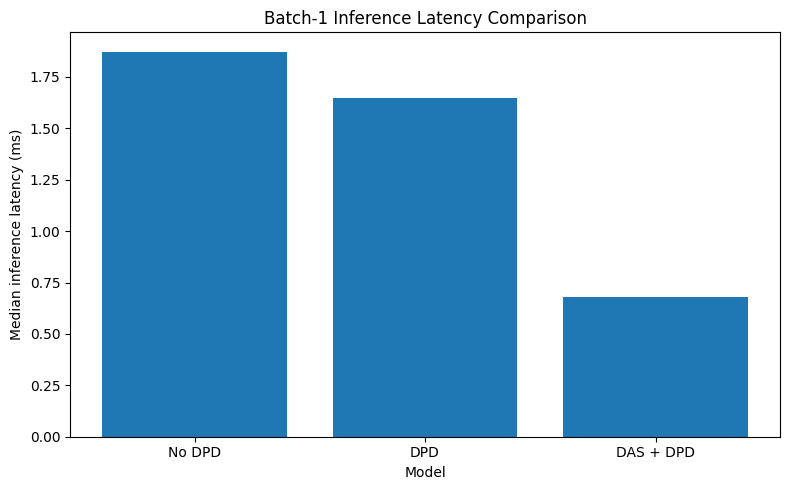

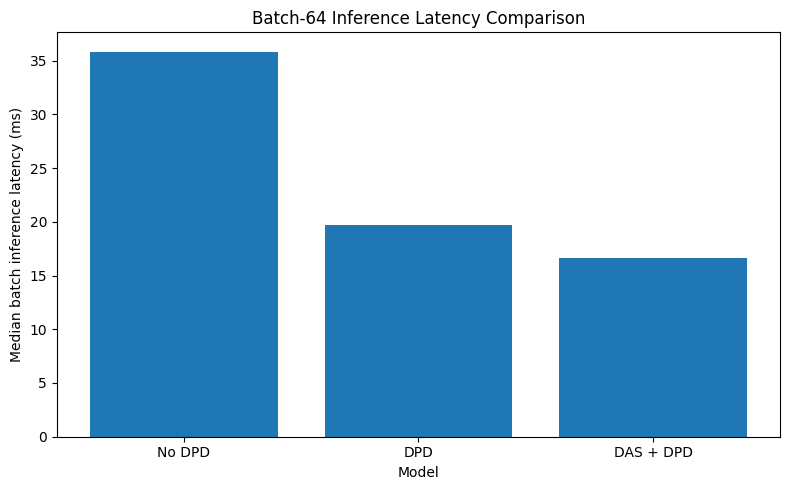

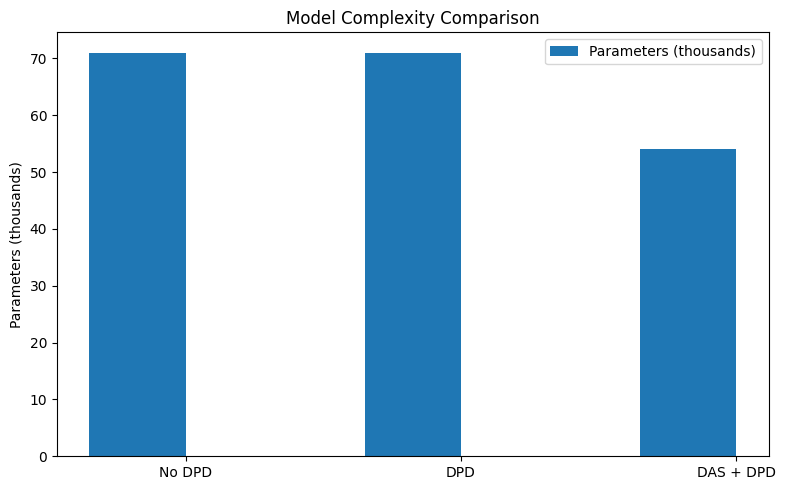

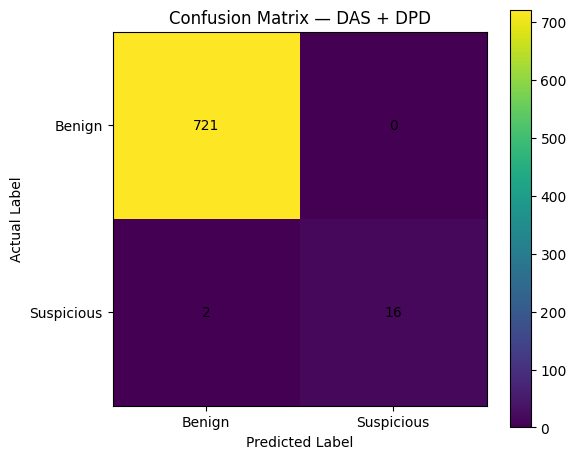


All figures saved in: /content/edge_arp_results/Paper_Figures
['Fig3_Model_Complexity.png', 'Fig1_Batch1_Latency.png', 'Fig2_Batch64_Latency.png', 'Fig4_Confusion_Matrix.png']


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = "/content/edge_arp_results"
OUT = os.path.join(BASE, "Paper_Figures")
os.makedirs(OUT, exist_ok=True)

df = pd.read_csv(
    os.path.join(BASE, "Final_Three_Model_Efficiency_Benchmark.csv")
)

models = df["Model"].tolist()

# Figure 1: Batch-1 inference latency
plt.figure(figsize=(8, 5))
plt.bar(models, df["Batch1_Median_ms"])
plt.ylabel("Median inference latency (ms)")
plt.xlabel("Model")
plt.title("Batch-1 Inference Latency Comparison")
plt.tight_layout()
plt.savefig(f"{OUT}/Fig1_Batch1_Latency.png", dpi=300)
plt.show()

# Figure 2: Batch-64 inference latency
plt.figure(figsize=(8, 5))
plt.bar(models, df["Batch64_Median_ms"])
plt.ylabel("Median batch inference latency (ms)")
plt.xlabel("Model")
plt.title("Batch-64 Inference Latency Comparison")
plt.tight_layout()
plt.savefig(f"{OUT}/Fig2_Batch64_Latency.png", dpi=300)
plt.show()

# Figure 3: Model complexity
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(models))
width = 0.35

ax.bar(x - width/2, df["Parameters"] / 1000,
       width, label="Parameters (thousands)")
ax.set_ylabel("Parameters (thousands)")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_title("Model Complexity Comparison")
ax.legend()
fig.tight_layout()
fig.savefig(f"{OUT}/Fig3_Model_Complexity.png", dpi=300)
plt.show()

# Figure 4: Confusion matrix
cm = np.array([[721, 0],
               [2, 16]])

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix — DAS + DPD")
plt.colorbar()
plt.xticks([0, 1], ["Benign", "Suspicious"])
plt.yticks([0, 1], ["Benign", "Suspicious"])
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]),
                 ha="center", va="center")

plt.tight_layout()
plt.savefig(f"{OUT}/Fig4_Confusion_Matrix.png", dpi=300)
plt.show()

print("\nAll figures saved in:", OUT)
print(os.listdir(OUT))

In [ ]:
import os

BASE = "/content/edge_arp_results"

for root, dirs, files in os.walk(BASE):
    for f in files:
        if "prob" in f.lower() or "prediction" in f.lower():
            print(os.path.join(root, f))

/content/edge_arp_results/ARP_UTFormer_test_probabilities.npy


In [ ]:
import numpy as np
import os

BASE = "/content/edge_arp_results"

p = np.load(
    os.path.join(BASE, "ARP_UTFormer_test_probabilities.npy")
)

y = np.load(os.path.join(BASE, "y_test.npy"))

print("Probability shape:", p.shape)
print("Label shape:", y.shape)
print("Probability sample:")
print(p[:5])
print("Label sample:")
print(y[:5])
print("Probability min/max:", p.min(), p.max())

Probability shape: (739,)
Label shape: (739,)
Probability sample:
[0.00465838 0.00398107 0.00416154 0.00398106 0.0041616 ]
Label sample:
[0 0 0 0 0]
Probability min/max: 0.0039314334 0.9914492


No DPD | ROC-AUC: 1.0 | PR-AUC: 1.0
DPD | ROC-AUC: 1.0 | PR-AUC: 1.0
DAS + DPD | ROC-AUC: 1.0 | PR-AUC: 1.0


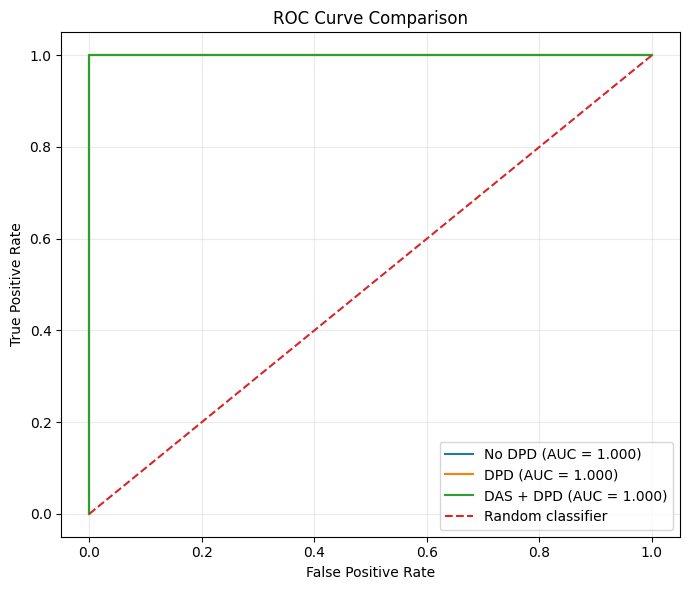

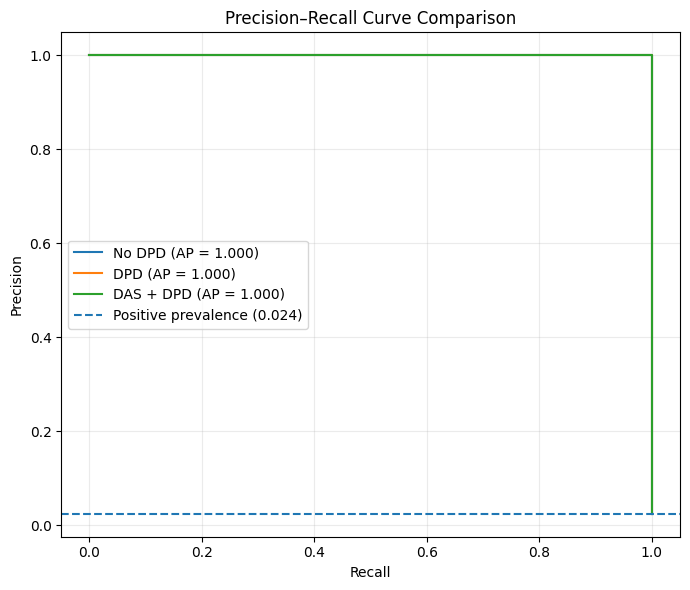


Saved all-model probability scores and curves in: /content/edge_arp_results/Paper_Figures


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve,
    average_precision_score
)

BASE = "/content/edge_arp_results"
OUT = os.path.join(BASE, "Paper_Figures")
os.makedirs(OUT, exist_ok=True)

device = torch.device("cpu")
torch.set_num_threads(1)

# Load test data
Xb = torch.tensor(
    np.load(f"{BASE}/X_bytes_test.npy"),
    dtype=torch.float32
)
Xf = torch.tensor(
    np.load(f"{BASE}/X_features_test.npy"),
    dtype=torch.float32
)
y = np.load(f"{BASE}/y_test.npy")

configs = {
    "No DPD": dict(heads=4, layers=2, ffn=128, gamma=1.0),
    "DPD": dict(heads=4, layers=2, ffn=128, gamma=0.5),
    "DAS + DPD": dict(heads=8, layers=1, ffn=256, gamma=0.5)
}

paths = {
    "No DPD": f"{BASE}/ARP_UTFormer_No_DPD_best.pt",
    "DPD": f"{BASE}/ARP_UTFormer_With_DPD_best.pt",
    "DAS + DPD": f"{BASE}/DAS/DAS_candidate_2.pt"
}

# Use the original saved probabilities for No DPD
probabilities = {
    "No DPD": np.load(
        f"{BASE}/ARP_UTFormer_test_probabilities.npy"
    )
}

for name in ["DPD", "DAS + DPD"]:

    cfg = configs[name]

    model = ARP_UTFormer(
        n_classes=2,
        n_bytes=42,
        n_features=10,
        dim=64,
        heads=cfg["heads"],
        layers=cfg["layers"],
        ffn=cfg["ffn"],
        gamma=cfg["gamma"],
        drop=0.1
    ).to(device)

    state = torch.load(
        paths[name],
        map_location=device,
        weights_only=True
    )
    model.load_state_dict(state)
    model.eval()

    with torch.inference_mode():
        logits = model(Xb, Xf)
        scores = torch.softmax(logits, dim=1)[:, 1]

    probabilities[name] = scores.cpu().numpy()

# Validate scores and save
for name, scores in probabilities.items():
    assert len(scores) == len(y), f"Length mismatch: {name}"
    assert np.isfinite(scores).all(), f"Invalid scores: {name}"

    print(
        name,
        "| ROC-AUC:", round(auc(*roc_curve(y, scores)[:2]), 6),
        "| PR-AUC:", round(average_precision_score(y, scores), 6)
    )

np.savez(
    f"{OUT}/All_Model_Test_Probabilities.npz",
    **probabilities
)

# ROC curve
plt.figure(figsize=(7, 6))

for name, scores in probabilities.items():
    fpr, tpr, _ = roc_curve(y, scores)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(f"{OUT}/Fig5_ROC_Comparison.png", dpi=300)
plt.show()

# Precision-Recall curve
plt.figure(figsize=(7, 6))

for name, scores in probabilities.items():
    precision, recall, _ = precision_recall_curve(y, scores)
    ap = average_precision_score(y, scores)
    plt.plot(recall, precision, label=f"{name} (AP = {ap:.3f})")

plt.axhline(
    y.mean(),
    linestyle="--",
    label=f"Positive prevalence ({y.mean():.3f})"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(f"{OUT}/Fig6_PR_Comparison.png", dpi=300)
plt.show()

print("\nSaved all-model probability scores and curves in:", OUT)

In [ ]:
import shutil
import os

folder = "/content/edge_arp_results"
zip_path = "/content/EdgeIIoT_ARP_Project_Results"

shutil.make_archive(zip_path, "zip", folder)

print("ZIP created:", zip_path + ".zip")
print("Size (MB):", round(
    os.path.getsize(zip_path + ".zip") / (1024**2), 2
))

ZIP created: /content/EdgeIIoT_ARP_Project_Results.zip
Size (MB): 3.59


In [ ]:
from google.colab import files

files.download("/content/EdgeIIoT_ARP_Project_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>